# Online Retail Customer Value: Stochastic Purchase Models, GLMs, Multivariate Analysis, and Sampling

## Question
A UK online gift retailer recorded every transaction from December 2009 to December 2011: about
1.07 million invoice lines from roughly 5,900 customers, many of them wholesalers. Using each customer's
behavior through May 2011, can we predict what they did from June to December 2011?

The retention team wants to know:
1. **What kinds of customers do we have?** Do segments built from past behavior differ in what they do next?
2. **Who is still active?** Which customers will buy again, and how often?
3. **What drives future spend?** Which behaviors predict spending, and does a regression beat a purchase-process model?
4. **How can we measure value cheaply?** If we could review only 500 customers, how should we sample them to estimate average spend?
5. **Who should get the retention budget?** Which customers are most valuable and most at risk of leaving?

## Methods
Data cleaning with reversed-order matching · PCA, Gaussian mixture segmentation, canonical correlation analysis,
MANOVA · BG/NBD model coded from the likelihood, Poisson-assumption test, discrete-time Markov chain with
likelihood-ratio tests · logistic and Gamma GLMs (two-part model), regression diagnostics, Duan smearing,
mixed-effects model · stratified sampling with Neyman allocation, ratio and regression estimators, Monte Carlo
design comparison · nonparametric and parametric bootstrap · gains-chart targeting evaluation

**Data:** Daqing Chen's [Online Retail II](https://archive.ics.uci.edu/dataset/502/online+retail+ii), UCI Machine Learning Repository (2012), CC BY 4.0.

In [ ]:
import json, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import display
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from statsmodels.multivariate.manova import MANOVA
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Project folder = the folder this notebook runs from
ROOT = Path.cwd()

DATA_DIR, FIG_DIR, RESULTS_DIR = ROOT / "data", ROOT / "figures", ROOT / "results"
for d in (DATA_DIR, FIG_DIR, RESULTS_DIR):
    d.mkdir(exist_ok=True)

# Find the Excel file in data/ or in the project folder
candidates = sorted(DATA_DIR.glob("online_retail*.xlsx")) + sorted(ROOT.glob("online_retail*.xlsx"))
if not candidates:
    raise FileNotFoundError(f"No online_retail*.xlsx found in {DATA_DIR} or {ROOT}")
DATA_FILE = candidates[0]
print("Project folder:", ROOT)
print("Data file:     ", DATA_FILE)

# Settings
CALIBRATION_END = "2011-06-01"
SEED = 2027
SAMPLE_SIZE = 500
N_SIM_REPS = 2000
N_BOOT = 200
N_PARAM_BOOT = 100
MAX_RECENCY = 6
N_SEGMENTS = None  # None = choose by BIC

rng = np.random.default_rng(SEED)
RESULTS = {}
warnings.filterwarnings("ignore", category=FutureWarning)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)

##  Load the data

We read the Online Retail II transactions (Dec 2009 – Dec 2011) from the Excel file and stack both sheets into one table. The first run saves a pickle copy to `data/`, so later runs load in seconds instead of re-reading Excel.

In [ ]:
DATA_FILE = DATA_DIR / "online_retail_II.xlsx"
CACHE = DATA_DIR / "online_retail_II.pkl"

if CACHE.exists():
    raw = pd.read_pickle(CACHE)
else:
    sheets = pd.read_excel(DATA_FILE, sheet_name=None,
                           dtype={"Invoice": str, "StockCode": str, "Description": str})
    raw = pd.concat(sheets, names=["sheet", "row"]).reset_index(level="sheet").reset_index(drop=True)
    raw.to_pickle(CACHE)

print(f"{len(raw):,} rows, {raw.shape[1]} columns")
display(raw.head())

1,067,371 rows, 9 columns


,sheet,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,Year 2009-2010,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,Year 2009-2010,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,Year 2009-2010,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,Year 2009-2010,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,Year 2009-2010,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


##  First look at the raw data

Before cleaning, we check what's in the data and what needs fixing: column types, missing values, how many invoices, customers, products and countries there are, and how many lines look problematic. Those include cancellations (invoices starting with "C"), zero or negative quantities and prices, exact duplicates, and stock codes that aren't real products. Real products have five digits plus an optional letter (e.g. 85123A); other codes are postage, fees, manual adjustments or tests, and we list the most common ones.

In [3]:
# Real products have five digits plus an optional letter suffix (e.g. 85123A).
# Anything else is postage, a fee, a manual adjustment or a test code.
PRODUCT_CODE = r"^\d{5}[A-Za-z]*$"

raw.info()

missing = raw.isna().sum().to_frame("missing")
missing["share"] = missing["missing"] / len(raw)
display(missing)

first_look = pd.Series({
    "invoices": raw["Invoice"].nunique(),
    "customers (non-missing IDs)": raw["Customer ID"].nunique(),
    "products (stock codes)": raw["StockCode"].nunique(),
    "countries": raw["Country"].nunique(),
    "cancellation lines (invoice starts with C)": raw["Invoice"].str.startswith("C").sum(),
    "lines with quantity <= 0": (raw["Quantity"] <= 0).sum(),
    "lines with price <= 0": (raw["Price"] <= 0).sum(),
    "lines with a non-product stock code": (~raw["StockCode"].str.match(PRODUCT_CODE)).sum(),
    "exact duplicate lines": raw.drop(columns="sheet").duplicated().sum(),
})
display(first_look.to_frame("count"))

print("Most common non-product codes:")
display(raw.loc[~raw["StockCode"].str.match(PRODUCT_CODE), ["StockCode", "Description"]]
        .value_counts().head(12).to_frame("lines"))

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 9 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   sheet        1067371 non-null  str           
 1   Invoice      1067371 non-null  str           
 2   StockCode    1067371 non-null  str           
 3   Description  1062989 non-null  str           
 4   Quantity     1067371 non-null  int64         
 5   InvoiceDate  1067371 non-null  datetime64[us]
 6   Price        1067371 non-null  float64       
 7   Customer ID  824364 non-null   float64       
 8   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(5)
memory usage: 73.3 MB


,missing,share
sheet,0,0.000000
Invoice,0,0.000000
StockCode,0,0.000000
Description,4382,0.004105
Quantity,0,0.000000
InvoiceDate,0,0.000000
Price,0,0.000000
Customer ID,243007,0.227669
Country,0,0.000000


,count
invoices,53628
customers (non-missing IDs),5942
products (stock codes),5305
countries,43
cancellation lines (invoice starts with C),19494
lines with quantity <= 0,22950
lines with price <= 0,6207
lines with a non-product stock code,6094
exact duplicate lines,34335


Most common non-product codes:


,,lines
StockCode,Description,
POST,POSTAGE,2115
DOT,DOTCOM POSTAGE,1444
M,Manual,1421
C2,CARRIAGE,279
D,Discount,177
S,SAMPLES,104
BANK CHARGES,Bank Charges,96
AMAZONFEE,AMAZON FEE,43
ADJUST,Adjustment by john on 26/01/2010 16,38


**Notes.** 243,007 lines (22.8%) have no customer ID and can't be linked to anyone, and 4,382 have no description. Cancellations, non-product codes and zero prices each need a decision in cleaning.

## Remove the overlap between the two sheets

The second sheet starts before the first one ends, so the days they share would be counted twice. We find the rows in the first sheet dated on or after the second sheet's start, check what share of them also appear identically in the second sheet, and drop them from the first sheet. The remaining rows form `df`, the single table used from here on, with each line given a `line_id`.

In [4]:
first_sheet, second_sheet = raw["sheet"].unique()[:2]
second_sheet_start = raw.loc[raw["sheet"] == second_sheet, "InvoiceDate"].min()
in_overlap = (raw["sheet"] == first_sheet) & (raw["InvoiceDate"] >= second_sheet_start)

overlap_rows = raw[in_overlap].drop(columns="sheet")
second_rows = raw[raw["sheet"] == second_sheet].drop(columns="sheet").drop_duplicates()
found_in_second = overlap_rows.merge(second_rows, how="left", indicator=True)["_merge"].eq("both").mean()

print(f"Rows in the overlap from '{first_sheet}': {in_overlap.sum():,}")
print(f"Share of them with an identical row in '{second_sheet}': {found_in_second:.1%}")

df = raw[~in_overlap].drop(columns="sheet")
df.index.name = "line_id"
print(f"Rows after removing the overlap: {len(df):,}")

Rows in the overlap from 'Year 2009-2010': 22,523
Share of them with an identical row in 'Year 2010-2011': 100.0%
Rows after removing the overlap: 1,044,848


## Clean the transactions

We rename the columns to short lowercase names, then apply five filters in order: drop lines without a customer ID, drop exact duplicates, set aside cancellations (kept in `cancels` to match against purchases later), keep real products only, and keep lines with positive quantity and price. After each filter we log the remaining rows, customers and revenue, so the cost of every cleaning decision is visible.

In [5]:
df = df.rename(columns={"Invoice": "invoice", "StockCode": "stock_code", "Description": "description",
                        "Quantity": "quantity", "InvoiceDate": "invoice_date", "Price": "price",
                        "Customer ID": "customer_id", "Country": "country"})

log = []
def record(step, frame):
    log.append({"step": step, "rows": len(frame), "customers": frame["customer_id"].nunique(),
                "revenue_£": (frame["quantity"] * frame["price"]).clip(lower=0).sum()})

record("Start (overlap removed)", df)

df = df.dropna(subset=["customer_id"])
record(" Drop lines without a customer ID", df)

df = df.drop_duplicates()
record("Drop exact duplicate lines", df)

is_cancel = df["invoice"].str.startswith("C")
cancels = df[is_cancel].copy()
df = df[~is_cancel]
record("Set aside cancellations (kept as returns)", df)

df = df[df["stock_code"].str.match(PRODUCT_CODE)]
record("Keep real products only", df)

df = df[(df["quantity"] > 0) & (df["price"] > 0)]
record("Keep positive quantity and price", df)

print(f"Cancellation lines set aside: {len(cancels):,}")

Cancellation lines set aside: 18,390


## Match cancellations and build the final tables

We pair each cancellation with an earlier purchase by the same customer, of the same product, in the same quantity, matching them one-to-one in date order so a single cancellation removes at most one purchase. Matched purchases are removed, since they never turned into real spending; partial cancellations (a different quantity) are not matched.

The cleaned data is then stored as two tables: `purchases` (one row per purchase line, with revenue) and `returns` (product cancellations, with their value). The cleaning log shows how many rows, customers and how much revenue remain after each step, followed by a summary of the final dataset and its date range.

In [6]:
cancels = cancels[cancels["stock_code"].str.match(PRODUCT_CODE)].copy()
cancels["qty"] = -cancels["quantity"]
key = ["customer_id", "stock_code", "qty"]

buys = df.assign(qty=df["quantity"]).sort_values("invoice_date")
buys["nth"] = buys.groupby(key).cumcount()
cancels = cancels.sort_values("invoice_date")
cancels["nth"] = cancels.groupby(key).cumcount()

pairs = buys.reset_index().merge(
    cancels[key + ["nth", "invoice_date"]].rename(columns={"invoice_date": "cancelled_at"}),
    on=key + ["nth"])
reversed_lines = pairs[pairs["invoice_date"] <= pairs["cancelled_at"]]

print(f"Purchase lines fully reversed by a later cancellation: {len(reversed_lines):,} "
      f"(£{(reversed_lines['quantity'] * reversed_lines['price']).sum():,.0f})")
display(reversed_lines.assign(value_gbp=reversed_lines["quantity"] * reversed_lines["price"])
        .nlargest(5, "value_gbp")[["customer_id", "stock_code", "description", "quantity", "value_gbp",
                                 "invoice_date", "cancelled_at"]])

df = df.drop(index=reversed_lines["line_id"])
record("Remove purchases fully reversed by a cancellation", df)

Purchase lines fully reversed by a later cancellation: 6,180 (£569,605)


,customer_id,stock_code,description,quantity,value_gbp,invoice_date,cancelled_at
6850,16446.0,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.6,2011-12-09 09:15:00,2011-12-09 09:27:00
4485,12346.0,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,77183.6,2011-01-18 10:01:00,2011-01-18 10:17:00
3824,15838.0,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,15818.4,2010-11-04 11:36:00,2010-12-02 14:23:00
4441,15749.0,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,6539.4,2011-01-11 12:55:00,2011-04-18 13:08:00
4439,15749.0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,1930,4921.5,2011-01-11 12:55:00,2011-04-18 13:08:00


In [7]:
%pip install jinja2
purchases = df.assign(customer_id=df["customer_id"].astype("int64"),
                      revenue=df["quantity"] * df["price"]).reset_index(drop=True)
returns = cancels.assign(customer_id=cancels["customer_id"].astype("int64"),
                         return_value=(cancels["quantity"] * cancels["price"]).abs()).reset_index(drop=True)

cleaning_log = pd.DataFrame(log)
cleaning_log["rows_removed"] = (-cleaning_log["rows"].diff()).fillna(0).astype(int)
display(cleaning_log.style.format({"rows": "{:,}", "customers": "{:,}", "revenue_£": "£{:,.0f}",
                                   "rows_removed": "{:,}"}))

print(f"Clean purchase lines: {len(purchases):,}  |  customers: {purchases['customer_id'].nunique():,}  |  "
      f"revenue: £{purchases['revenue'].sum():,.0f}")
print(f"Dates: {purchases['invoice_date'].min():%d %b %Y} to {purchases['invoice_date'].max():%d %b %Y}")


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


,step,rows,customers,revenue_£,rows_removed
0,Start (overlap removed),"1,044,848","5,942","£20,534,115",0
1,Drop lines without a customer ID,"809,561","5,942","£17,431,551","235,287"
2,Drop exact duplicate lines,"797,885","5,942","£17,374,804","11,676"
3,Set aside cancellations (kept as returns),"779,495","5,881","£17,374,804","18,390"
4,Keep real products only,"776,637","5,853","£17,068,568","2,858"
5,Keep positive quantity and price,"776,577","5,852","£17,068,568",60
6,Remove purchases fully reversed by a cancellation,"770,397","5,839","£16,498,963","6,180"


Clean purchase lines: 770,397  |  customers: 5,839  |  revenue: £16,498,963
Dates: 01 Dec 2009 to 09 Dec 2011


## Build the customer table

We split the timeline at `CALIBRATION_END` (1 June 2011). Everything before that date is the **calibration period**, which the models learn from; everything from 1 June to the last purchase in December 2011 is the **holdout period**, which we keep aside to check the predictions. The table has one row per customer who bought at least once in calibration, and a "purchase" is a distinct purchase day, so several invoices on the same day count as one shopping occasion.

For each customer we compute three groups of columns. The **BG/NBD inputs** are `frequency` (number of repeat purchase days), `t_x` (weeks from first to last purchase, i.e. recency) and `T` (weeks from first purchase to the end of calibration, i.e. how long we've been able to observe them). The **behaviour features** describe how they shop: total spend, average order value, spend and items per purchase day, average unit price, number of distinct products, main country, share of purchase days in Q4, and return rate (value returned as a share of value bought plus returned). The skewed features also get log versions for the PCA and segmentation later on. Finally, the **holdout outcomes** record what each customer actually did after 1 June: number of purchase days, total spend, and whether they bought at all. These are only used to evaluate the models, never to fit them.

The cell prints the two periods, the number of customers and the share who bought again, then shows the first few rows and summary statistics of the table.

In [8]:
from dataclasses import dataclass
import pandas as pd


# Study window: calibration = first purchase up to CALIBRATION_END, holdout = CALIBRATION_END to the last purchase
@dataclass(frozen=True)
class StudyWindow:
    start: pd.Timestamp
    calibration_end: pd.Timestamp
    holdout_end: pd.Timestamp

    @classmethod
    def from_data(cls, purchases, calibration_end, date_col="invoice_date"):
        dates = purchases[date_col]
        start = dates.min().normalize()
        holdout_end = dates.max().normalize() + pd.Timedelta(days=1)
        calibration_end = pd.Timestamp(calibration_end)
        if not start < calibration_end < holdout_end:
            raise ValueError("CALIBRATION_END must fall inside the data's date range")
        return cls(start, calibration_end, holdout_end)

    @property
    def holdout_weeks(self):
        return (self.holdout_end - self.calibration_end).days / 7


# One row per customer with a calibration purchase; a "purchase" is a distinct purchase day
def build_customer_table(purchases, returns, window):
    p = purchases.assign(day=purchases["invoice_date"].dt.normalize())
    calib = p[p["day"] < window.calibration_end]
    hold = p[(p["day"] >= window.calibration_end) & (p["day"] < window.holdout_end)]

    calib_days = (calib.groupby(["customer_id", "day"], as_index=False)
                       .agg(spend=("revenue", "sum"), n_invoices=("invoice", "nunique"),
                            n_lines=("revenue", "size")))

    g = calib_days.groupby("customer_id")
    first, last = g["day"].min(), g["day"].max()
    customers = pd.DataFrame({"first_purchase": first, "last_purchase": last,
                              "n_purchase_days": g.size(), "n_invoices": g["n_invoices"].sum(),
                              "calib_spend": g["spend"].sum()})

    # BG/NBD inputs (weeks)
    customers["frequency"] = customers["n_purchase_days"] - 1
    customers["t_x"] = (last - first).dt.days / 7
    customers["T"] = (window.calibration_end - first).dt.days / 7

    # Behaviour features
    units = calib.groupby("customer_id")["quantity"].sum()
    customers["aov"] = customers["calib_spend"] / customers["n_invoices"]                # per invoice
    customers["spend_per_occasion"] = customers["calib_spend"] / customers["n_purchase_days"]
    customers["items_per_order"] = units / customers["n_purchase_days"]
    customers["avg_unit_price"] = customers["calib_spend"] / units
    customers["n_products"] = calib.groupby("customer_id")["stock_code"].nunique()
    customers["country"] = (calib.groupby(["customer_id", "country"]).size().reset_index(name="n")
                                 .sort_values(["customer_id", "n"], ascending=[True, False])
                                 .drop_duplicates("customer_id").set_index("customer_id")["country"])
    customers["is_uk"] = customers["country"] == "United Kingdom"
    customers["q4_share"] = (calib_days.assign(q4=calib_days["day"].dt.month >= 10)
                                       .groupby("customer_id")["q4"].mean())

    ret_value = (returns[returns["invoice_date"] < window.calibration_end]
                 .groupby("customer_id")["return_value"].sum()
                 .reindex(customers.index, fill_value=0.0))
    customers["return_rate"] = ret_value / (customers["calib_spend"] + ret_value)

    # Logged versions for PCA
    customers["log_orders"] = np.log(customers["n_purchase_days"])
    customers["log_aov"] = np.log(customers["spend_per_occasion"])
    customers["log_items_per_order"] = np.log(customers["items_per_order"])
    customers["log_products"] = np.log(customers["n_products"])
    customers["log_avg_price"] = np.log(customers["avg_unit_price"])

    # Holdout outcomes
    hg = hold.groupby("customer_id")
    customers["holdout_purchases"] = hg["day"].nunique().reindex(customers.index, fill_value=0).astype(int)
    customers["holdout_spend"] = hg["revenue"].sum().reindex(customers.index, fill_value=0.0)
    customers["holdout_active"] = customers["holdout_purchases"] > 0
    return customers, calib_days


window = StudyWindow.from_data(purchases, CALIBRATION_END)
customers, calib_days = build_customer_table(purchases, returns, window)

print(f"Calibration: {window.start:%d %b %Y} to {window.calibration_end - pd.Timedelta(days=1):%d %b %Y}")
print(f"Holdout:     {window.calibration_end:%d %b %Y} to {window.holdout_end - pd.Timedelta(days=1):%d %b %Y} "
      f"({window.holdout_weeks:.1f} weeks)")
print(f"Customers in the calibration population: {len(customers):,}")
print(f"Share who bought again in the holdout:  {customers['holdout_active'].mean():.1%}")

display(customers[["frequency", "t_x", "T", "calib_spend", "aov", "n_products", "return_rate", "country",
                   "holdout_purchases", "holdout_spend"]].head())
display(customers[["n_purchase_days", "calib_spend", "aov", "n_products", "return_rate",
                   "holdout_purchases", "holdout_spend"]].describe().T)

RESULTS["data"] = {"raw_rows": int(len(raw)), "clean_rows": int(len(purchases)),
                   "reversed_lines_removed": int(len(reversed_lines)),
                   "customers": int(len(customers)),
                   "holdout_active_share": float(customers["holdout_active"].mean())}

Calibration: 01 Dec 2009 to 31 May 2011
Holdout:     01 Jun 2011 to 09 Dec 2011 (27.4 weeks)
Customers in the calibration population: 4,898
Share who bought again in the holdout:  52.9%


,frequency,t_x,T,calib_spend,aov,n_products,return_rate,country,holdout_purchases,holdout_spend
customer_id,,,,,,,,,,
12346,1,16.857143,65.142857,169.36,84.68,24,0.997811,United Kingdom,0,0.00
12347,3,22.571429,30.428571,2434.96,608.74,90,0.000000,Iceland,4,2486.57
12348,3,27.142857,35.285714,1388.40,347.10,24,0.000000,Finland,1,270.00
12349,1,26.000000,56.857143,2221.14,1110.57,89,0.010756,Italy,1,1457.55
12350,0,0.000000,17.000000,294.40,294.40,16,0.000000,Norway,0,0.00


,count,mean,std,min,25%,50%,75%,max
n_purchase_days,4898.0,4.657411,7.673940,1.00,1.000000,2.00,5.000000,163.000000
calib_spend,4898.0,2300.676925,10209.848407,1.55,310.595000,730.39,1889.227500,384113.450000
aov,4898.0,363.629486,501.516223,1.55,173.261875,276.67,410.439557,12425.450000
n_products,4898.0,70.011637,96.925113,1.00,17.000000,40.00,87.000000,1960.000000
return_rate,4898.0,0.020541,0.064047,0.00,0.000000,0.00,0.014857,0.997811
holdout_purchases,4898.0,1.647815,3.417378,0.00,0.000000,1.00,2.000000,84.000000
holdout_spend,4898.0,911.324524,5206.820017,0.00,0.000000,110.58,699.005000,195015.190000


## Overview of the data

Before modelling, we take a quick look at the whole period. The first two charts show monthly revenue and the number of customers who bought each month, with a dashed line marking where the holdout period starts. They let us check for seasonality, and in particular whether the holdout (June to December 2011) includes the busy pre-Christmas months. That matters because a model fitted on calibration data assumes customers buy at a steady rate, so a seasonal peak in the holdout can make its predictions look too low.

The third chart shows how many purchase occasions (distinct purchase days) each customer had in the calibration period, with everything above 20 grouped into one bar. It shows how skewed purchase frequency is: we expect many customers to have bought only once or twice and a small group of frequent buyers, often wholesalers. One-time buyers have `frequency = 0`, which the BG/NBD model is designed to handle, but they are also the customers we know least about.

The figure is saved as `00_overview.png` in the `figures/` folder.

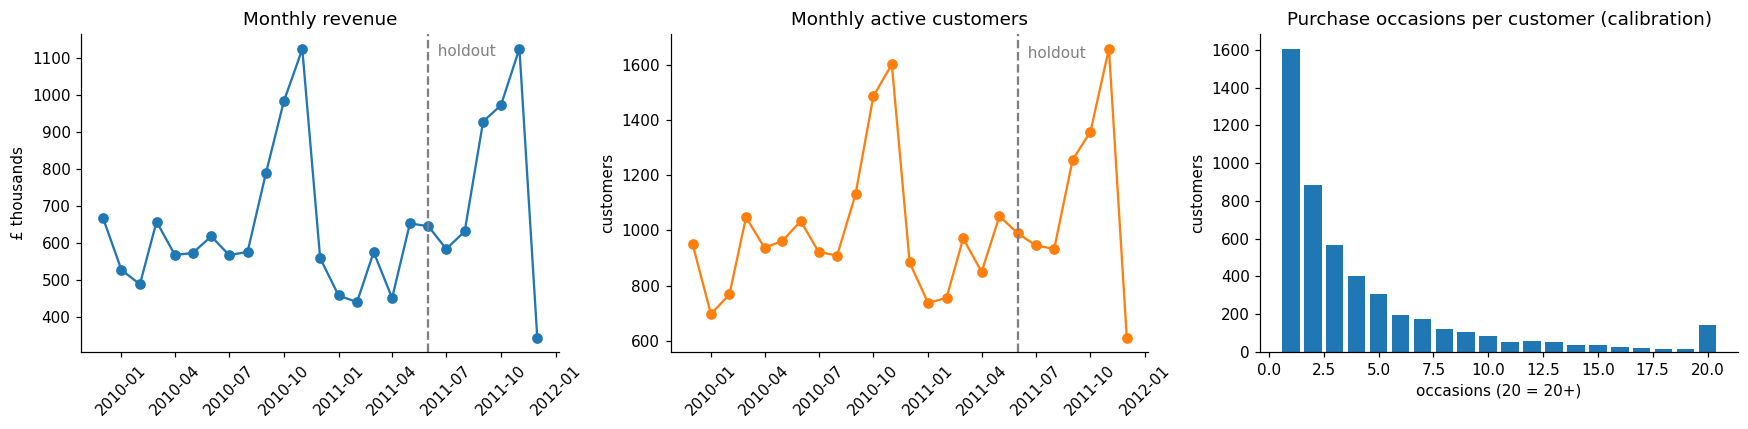

In [9]:
monthly = (purchases.assign(month=purchases["invoice_date"].dt.to_period("M").dt.to_timestamp())
           .groupby("month").agg(revenue=("revenue", "sum"), customers=("customer_id", "nunique")))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(monthly.index, monthly["revenue"] / 1e3, marker="o")
axes[0].set(title="Monthly revenue", ylabel="£ thousands")
axes[1].plot(monthly.index, monthly["customers"], marker="o", color="C1")
axes[1].set(title="Monthly active customers", ylabel="customers")
for ax in axes[:2]:
    ax.axvline(window.calibration_end, color="grey", ls="--")
    ax.text(window.calibration_end, ax.get_ylim()[1] * 0.95, "  holdout", color="grey")
    ax.tick_params(axis="x", rotation=45)
counts = customers["n_purchase_days"].clip(upper=20).value_counts().sort_index()
axes[2].bar(counts.index, counts.values)
axes[2].set(title="Purchase occasions per customer (calibration)", xlabel="occasions (20 = 20+)",
            ylabel="customers")
fig.tight_layout()
savefig(fig, "00_overview")

**Notes.** Revenue and active customers follow the same seasonal pattern. Most months bring in about £450k–650k from 700–1,050 customers, but both climb from September and peak in November (around £1.1M and 1,600 customers in both 2010 and 2011). The sharp drop in December 2011 is not a real decline: the data ends on 9 December, so that month is incomplete. The important point for modelling is that the holdout covers the autumn peak, while calibration ends in a quiet stretch, so a model that assumes a steady purchase rate is likely to underpredict holdout purchases. The `q4_share` feature partly captures which customers lean on the Christmas season.

Purchase frequency is very skewed. The largest group, about 1,600 customers (roughly a third), bought on only one day in calibration, and the counts fall off quickly after that. A small tail of around 140 customers bought on 20 or more days; these are likely the wholesalers, and they matter far more for revenue than their numbers suggest.

## Multivariate analysis

Here we describe each customer's buying style during the calibration period using six behaviour features. Amounts that are very skewed (a few customers have huge values) are put on a log scale. All features are then standardised, meaning each is rescaled to the same range, so that features measured in large units like pounds don't dominate the PCA just because their numbers are bigger.

We leave out items per occasion on purpose. Items per occasion is just spend per occasion divided by average unit price, and on the log scale that becomes a simple subtraction. So it carries no new information: once you know the other two, you know it exactly. Including it would make the features perfectly redundant, which breaks the canonical correlation analysis later in this section, because that method can't be computed when one feature is an exact combination of others.

### Feature correlations

These are the six features we use: number of purchase occasions, spend per occasion, number of distinct products, and average unit price (all on a log scale), plus return rate and the share of purchases made in Q4. We also give each feature a readable name for the charts.

The heatmap shows how strongly each pair of features moves together, from −1 (opposite directions) to +1 (same direction). This is a quick check before PCA: features that are strongly correlated carry overlapping information, which PCA can combine into fewer components. The figure is saved as `01_feature_correlations.png`.

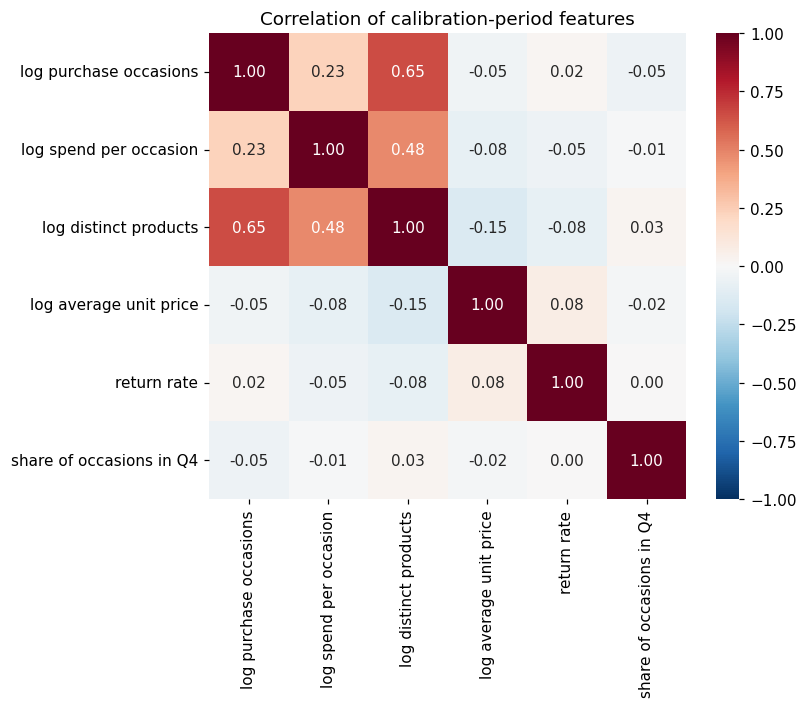

In [10]:
FEATURES = ["log_orders", "log_aov", "log_products", "log_avg_price", "return_rate", "q4_share"]
FEATURE_LABELS = {"log_orders": "log purchase occasions", "log_aov": "log spend per occasion",
                  "log_items_per_order": "log items per occasion", "log_products": "log distinct products",
                  "log_avg_price": "log average unit price", "return_rate": "return rate",
                  "q4_share": "share of occasions in Q4"}

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(customers[FEATURES].rename(columns=FEATURE_LABELS).corr(), annot=True, fmt=".2f",
            cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation of calibration-period features")
savefig(fig, "01_feature_correlations")

### Principal component analysis (PCA)

PCA turns our six related features into a smaller set of new, uncorrelated summary scores called components. Each component is a weighted mix of the original features, and the first one captures as much of the variation between customers as possible, the second captures the most of what's left, and so on.

We first standardise the features, then keep the smallest number of components that together explain at least 80% of the variation. Each customer's scores on these components are saved as new columns (`PC1`, `PC2`, …) for the segmentation that follows.

The left chart (scree plot) shows how much variation each component explains on its own (bars) and in total (line). The dashed line marks the 80% cut-off. The dotted line is the Kaiser rule: a component above it explains more than a single original feature would, so it's worth keeping.

The right chart shows the loadings, which are the correlations between each original feature and each component. Large positive or negative values tell us what a component stands for, for example a component that loads heavily on purchase occasions and number of products can be read as "how much a customer buys from us". The figure is saved as `02_pca.png`, and the cell prints how many components we kept and how much variation they explain.

Keeping 4 components, explaining 82.6% of the variance.


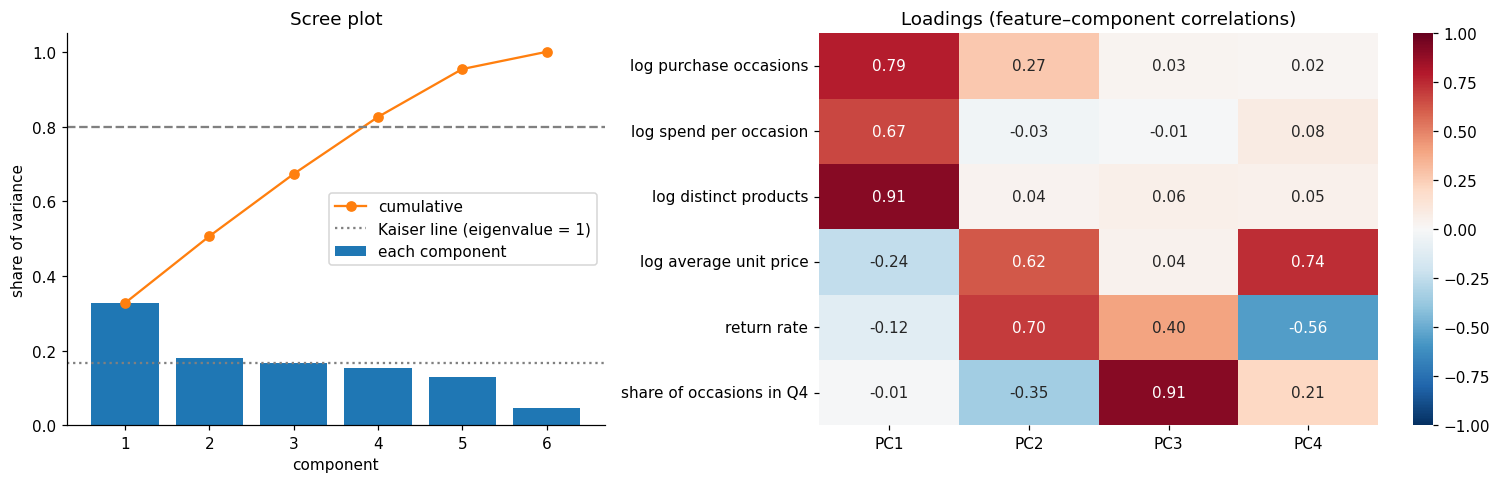

In [11]:
Z = StandardScaler().fit_transform(customers[FEATURES])
pca = PCA().fit(Z)
evr = pca.explained_variance_ratio_
n_pc = int(np.searchsorted(np.cumsum(evr), 0.80) + 1)
pc_names = [f"PC{i + 1}" for i in range(n_pc)]

loadings = pd.DataFrame(pca.components_[:n_pc].T * np.sqrt(pca.explained_variance_[:n_pc]),
                        index=[FEATURE_LABELS[f] for f in FEATURES], columns=pc_names)
scores = pca.transform(Z)[:, :n_pc]
customers[pc_names] = scores

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 1.3]})
k = np.arange(1, len(evr) + 1)
axes[0].bar(k, evr, label="each component")
axes[0].plot(k, np.cumsum(evr), "o-", color="C1", label="cumulative")
axes[0].axhline(0.8, color="grey", ls="--")
axes[0].axhline(1 / len(FEATURES), color="grey", ls=":", label="Kaiser line (eigenvalue = 1)")
axes[0].set(title="Scree plot", xlabel="component", ylabel="share of variance")
axes[0].legend(loc="center right")
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Loadings (feature–component correlations)")
fig.tight_layout()
savefig(fig, "02_pca")

print(f"Keeping {n_pc} components, explaining {np.cumsum(evr)[n_pc - 1]:.1%} of the variance.")
RESULTS["pca"] = {"n_components": n_pc, "variance_explained": float(np.cumsum(evr)[n_pc - 1])}

**Notes.** We keep four components, which together explain about 83% of the variation. There is no sharp "elbow" in the scree plot: after the first component, each one adds a similar amount (around 13–18%). That means the features don't collapse neatly into one or two dimensions, apart from the group of size-related features in PC1. The Kaiser rule would keep only two or three components (PC3 sits right on the line), so the 80% rule is the more generous choice here.

The components are fairly easy to read from the loadings:

- **PC1 – customer size (33%).** High on purchase occasions, spend per occasion and especially number of distinct products. Customers who score high buy often, spend more each time and buy a wide range of items, which fits the wholesalers. They also lean slightly towards cheaper items.
- **PC2 – pricier items and returns (18%).** High on average unit price and return rate, and slightly lower on Q4 share. These customers buy more expensive items and send more back.
- **PC3 – Christmas shoppers (17%).** Almost entirely the share of purchases made in Q4, with some link to returns. It separates customers who mainly buy in the run-up to Christmas.
- **PC4 – pricier items without returns (15%).** High on unit price but negative on return rate, so it splits the high-price customers from PC2 into those who keep what they buy and those who return it. This one is the hardest to interpret, so we should treat it with some caution.

### Customer segmentation

Next we group customers into segments based on their PCA scores, using a Gaussian mixture model. This model assumes the customers come from a few overlapping groups, each shaped like a cloud of points, and works out which group each customer most likely belongs to.

To choose the number of segments, we fit models with 1 to 8 segments and compare their BIC, a score that rewards fitting the data well but penalises using more segments than needed (lower is better). We pick the number with the lowest BIC, with at least two segments, unless `N_SEGMENTS` is set by hand in the settings. The segments are then renamed S1, S2, … in order of median calibration spend, so S1 is always the lowest-spending group.

The left chart shows BIC for each number of segments, with the chosen number marked. The right chart plots every customer on the first two components, coloured by segment, to show how the groups sit relative to each other. The figure is saved as `03_segments.png`.

The table then profiles each segment: its size and share of customers, typical purchase occasions, spend, items, number of products and unit price (medians), average return rate and Q4 share, share of UK customers, and the share who bought again in the holdout. That last column is the first check of whether segments built from past behaviour really differ in what customers do next.

,customers,share,median_occasions,median_spend_per_occasion,median_items_per_occasion,median_products,median_unit_price,mean_return_rate,mean_q4_share,uk_share,holdout_active_rate
segment,,,,,,,,,,,
S1,914,0.19,1.0,213.92,117.50,16.0,1.95,0.00,0.00,0.91,0.27
S2,562,0.11,1.0,233.65,138.00,21.0,1.79,0.00,1.00,0.93,0.30
S3,294,0.06,2.0,286.60,159.43,25.0,1.90,0.06,0.00,0.89,0.43
S4,289,0.06,3.0,235.59,125.33,23.0,2.12,0.18,0.56,0.93,0.47
S5,640,0.13,2.0,272.34,165.67,37.0,1.80,0.00,0.00,0.91,0.52
S6,1374,0.28,4.0,299.64,175.30,68.0,1.78,0.00,0.37,0.93,0.67
S7,825,0.17,9.0,317.14,188.50,121.0,1.89,0.03,0.35,0.92,0.81


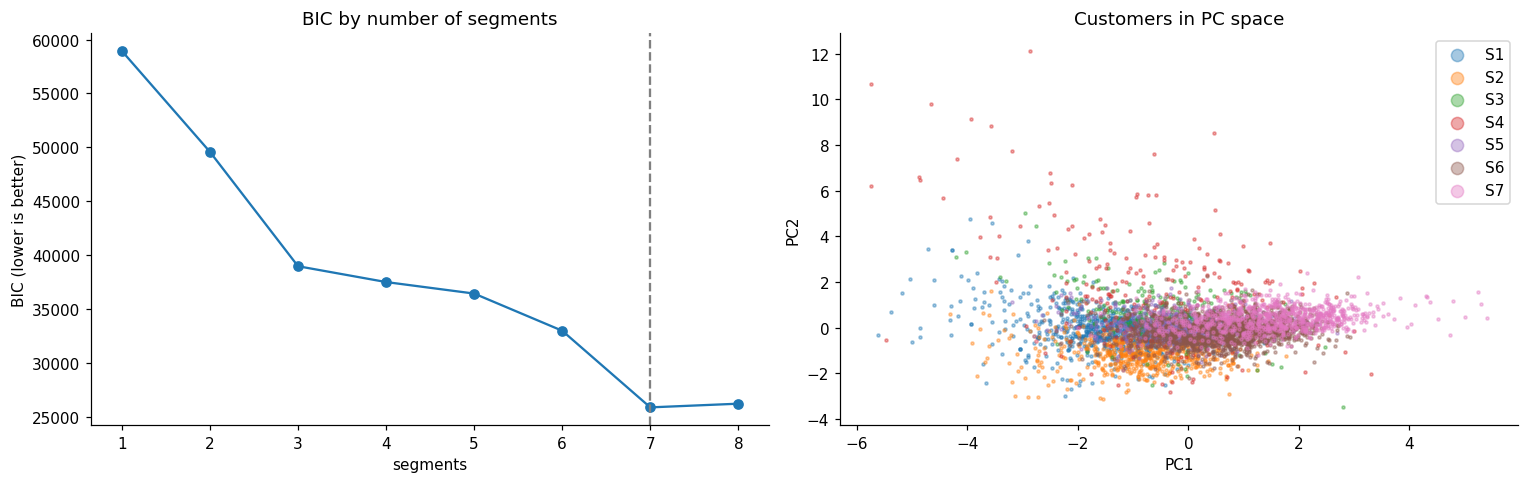

In [12]:
ks = list(range(1, 9))
bic = [GaussianMixture(k, covariance_type="full", n_init=5, random_state=SEED).fit(scores).bic(scores)
       for k in ks]
best_k = N_SEGMENTS or ks[1:][int(np.argmin(bic[1:]))]

gmm = GaussianMixture(best_k, covariance_type="full", n_init=10, random_state=SEED).fit(scores)
raw_labels = gmm.predict(scores)
# Order segments by median calibration spend so S1 is the lowest-value segment.
order = (pd.Series(customers["calib_spend"].to_numpy()).groupby(raw_labels).median()
         .sort_values().index)
relabel = {old: f"S{i + 1}" for i, old in enumerate(order)}
customers["segment"] = pd.Series(raw_labels, index=customers.index).map(relabel)
SEGMENTS = sorted(customers["segment"].unique())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(ks, bic, "o-")
axes[0].axvline(best_k, color="grey", ls="--")
axes[0].set(title="BIC by number of segments", xlabel="segments", ylabel="BIC (lower is better)")
for seg in SEGMENTS:
    m = customers["segment"] == seg
    axes[1].scatter(customers.loc[m, "PC1"], customers.loc[m, "PC2"] if n_pc > 1 else 0,
                    s=4, alpha=0.4, label=seg)
axes[1].set(title="Customers in PC space", xlabel="PC1", ylabel="PC2")
axes[1].legend(markerscale=4)
fig.tight_layout()
savefig(fig, "03_segments")

profile = customers.groupby("segment").agg(
    customers=("segment", "size"),
    median_occasions=("n_purchase_days", "median"),
    median_spend_per_occasion=("aov", "median"),
    median_items_per_occasion=("items_per_order", "median"),
    median_products=("n_products", "median"),
    median_unit_price=("avg_unit_price", "median"),
    mean_return_rate=("return_rate", "mean"),
    mean_q4_share=("q4_share", "mean"),
    uk_share=("is_uk", "mean"),
    holdout_active_rate=("holdout_active", "mean"),
)
profile.insert(1, "share", profile["customers"] / profile["customers"].sum())
display(profile.round(2))
RESULTS["segments"] = {"k": best_k, "sizes": profile["customers"].astype(int).to_dict()}

**Notes.** BIC falls steeply up to three segments, then only slowly from three to six, then drops sharply again at seven before rising slightly at eight. So the model picks seven segments, and since eight is worse, seven is a real minimum rather than just the largest number we tried.

That sudden drop at seven is worth a closer look, though. A jump like this can happen when one segment fits a tight group of customers with nearly identical values, rather than a genuinely different type of customer. One-time buyers are a likely example: they all have exactly one purchase occasion and a Q4 share of either 0 or 1, and many have no returns. The segment profile table should show whether one of the seven segments is mostly one-time buyers.

In the scatter plot, the segments overlap a lot. This is partly expected, because the segments were built from four components and the plot only shows the first two. Some patterns are still visible: S7 sits on the right (high PC1, the largest and broadest buyers), S1 and S2 sit on the left (smaller customers), with S2 lower on PC2 (cheaper items, fewer returns). S4 is spread out widely, especially upwards on PC2, so it seems to collect unusual customers with high prices or high return rates rather than forming a tight group.

### Canonical correlation analysis (CCA)

CCA asks how strongly past behaviour is linked to future behaviour as a whole, rather than one variable at a time.

**Preparing the data.** We first add three columns the analysis needs: recency (weeks between a customer's last purchase and the end of calibration), tenure (weeks since their first purchase), and the number of distinct products each customer bought in the holdout. On the calibration side we use the six behaviour features plus recency and tenure. On the holdout side we use three outcomes: number of purchase days, total spend and number of distinct products, each on a log(1 + x) scale because many customers have zeros.

**How CCA works.** It finds a weighted mix of the calibration features and a weighted mix of the holdout outcomes that are as strongly correlated with each other as possible. This is the first canonical pair. It then finds a second pair that captures a different link, and a third, since there are three holdout outcomes. We write the method out ourselves: both sides are standardised, and the pairs come from a matrix decomposition of their correlations. Signs are flipped so that each holdout variate goes up when future activity goes up, which makes the charts easier to read.

**Reading the output.** The table tests each pair with Bartlett's chi-square test (Wilks' lambda). A small p-value means that pair and the ones after it carry a real link rather than noise, so it tells us how many separate links exist between past and future behaviour. The two heatmaps show structure correlations, the correlation between each original variable and its side's canonical variate, which tells us what each pair is made of. The last chart plots the first canonical pair against each other, with its correlation in the title, to show how tight the main link is. The figure is saved as `04_cca.png`.

,canonical_r,wilks_lambda,chi2,df,p_value
pair,,,,,
CV1,0.6728,0.3314,5401.9643,24,0.0
CV2,0.5721,0.6055,2453.8978,14,0.0
CV3,0.3160,0.9001,514.6416,6,0.0


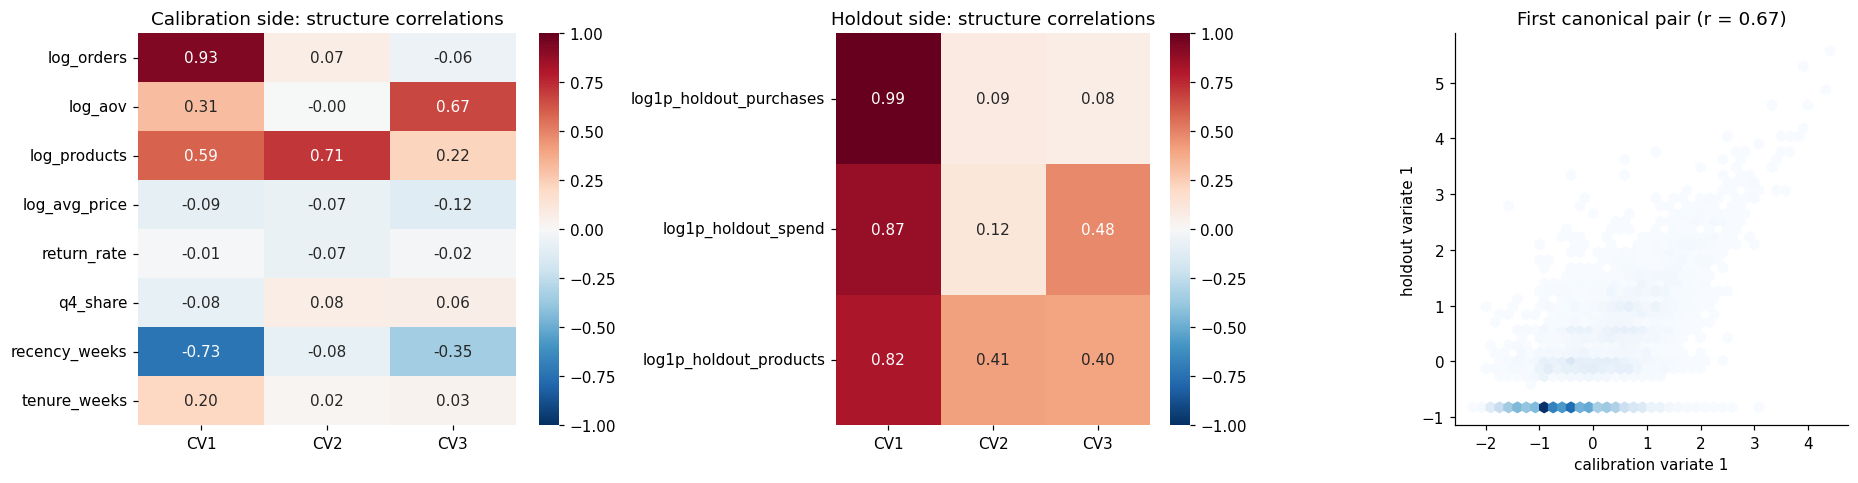

In [14]:
# Columns the CCA needs; created here if the customer-table cell didn't make them
customers["recency_weeks"] = customers["T"] - customers["t_x"]   # weeks from last purchase to calibration end
customers["tenure_weeks"] = customers["T"]                       # weeks from first purchase to calibration end
if "holdout_products" not in customers:
    _day = purchases["invoice_date"].dt.normalize()
    _hold = purchases[(_day >= window.calibration_end) & (_day < window.holdout_end)]
    customers["holdout_products"] = (_hold.groupby("customer_id")["stock_code"].nunique()
                                     .reindex(customers.index, fill_value=0).astype(int))


def canonical_correlation(X, Y):
    """Canonical correlation analysis on standardised X and Y."""
    Xs = ((X - X.mean()) / X.std(ddof=1)).to_numpy()
    Ys = ((Y - Y.mean()) / Y.std(ddof=1)).to_numpy()
    n, p, q = len(Xs), Xs.shape[1], Ys.shape[1]
    k = min(p, q)

    Rxx, Ryy = np.corrcoef(Xs, rowvar=False), np.corrcoef(Ys, rowvar=False)
    Rxy = Xs.T @ Ys / (n - 1)
    Lx_inv = np.linalg.inv(np.linalg.cholesky(Rxx))
    Ly_inv = np.linalg.inv(np.linalg.cholesky(Ryy))
    u, r, vt = np.linalg.svd(Lx_inv @ Rxy @ Ly_inv.T)
    A = Lx_inv.T @ u[:, :k]        # weights for the calibration side
    B = Ly_inv.T @ vt.T[:, :k]     # weights for the holdout side
    r = r[:k]

    # Flip signs so each holdout variate correlates positively with the holdout outcomes
    sign = np.sign((Ryy @ B).sum(axis=0))
    A, B = A * sign, B * sign

    names = [f"CV{i + 1}" for i in range(k)]
    x_structure = pd.DataFrame(Rxx @ A, index=X.columns, columns=names)
    y_structure = pd.DataFrame(Ryy @ B, index=Y.columns, columns=names)

    # Bartlett's chi-square test (Wilks' lambda): are pairs i, i+1, ... all zero?
    rows = []
    for i in range(k):
        wilks = np.prod(1 - r[i:] ** 2)
        chi2 = -(n - 1 - (p + q + 1) / 2) * np.log(wilks)
        df = (p - i) * (q - i)
        rows.append({"pair": names[i], "canonical_r": r[i], "wilks_lambda": wilks,
                     "chi2": chi2, "df": df, "p_value": stats.chi2.sf(chi2, df)})
    tests = pd.DataFrame(rows).set_index("pair")

    return {"canonical_correlations": r, "tests": tests, "x_structure": x_structure,
            "y_structure": y_structure, "U": Xs @ A, "V": Ys @ B}


X_cca = customers[FEATURES + ["recency_weeks", "tenure_weeks"]]
Y_cca = pd.DataFrame({"log1p_holdout_purchases": np.log1p(customers["holdout_purchases"]),
                      "log1p_holdout_spend": np.log1p(customers["holdout_spend"]),
                      "log1p_holdout_products": np.log1p(customers["holdout_products"])},
                     index=customers.index)
cca = canonical_correlation(X_cca, Y_cca)

display(cca["tests"].round(4))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), gridspec_kw={"width_ratios": [1.2, 1, 1]})
sns.heatmap(cca["x_structure"], annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Calibration side: structure correlations")
sns.heatmap(cca["y_structure"], annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Holdout side: structure correlations")
axes[2].hexbin(cca["U"][:, 0], cca["V"][:, 0], gridsize=40, cmap="Blues", mincnt=1)
axes[2].set(title=f"First canonical pair (r = {cca['canonical_correlations'][0]:.2f})",
            xlabel="calibration variate 1", ylabel="holdout variate 1")
fig.tight_layout()
savefig(fig, "04_cca")
RESULTS["cca"] = {"canonical_correlations": [float(c) for c in cca["canonical_correlations"]]}

**Notes.** The first canonical pair has a correlation of 0.67, so past behaviour and future behaviour are clearly linked. In plain terms, the calibration mix and the holdout mix share about 45% of their variation (0.67²).

**What the first pair means.** On the calibration side, it is driven by number of purchase occasions (0.93) and recency (−0.73), with some contribution from number of products (0.59). On the holdout side, it lines up with all three outcomes, especially number of purchase days (0.99). This is the classic pattern behind purchase models: customers who bought often and recently keep buying, and those who haven't bought in a long time tend not to come back. Average unit price, return rate and Q4 share are close to zero on every pair, so they tell us little about future activity.

**The weaker pairs.** The second pair links buying a wide range of products in the past (0.71) to buying a wide range in the holdout (0.41), regardless of how often. The third links spending a lot per occasion in the past (0.67) to higher holdout spend (0.48). These are smaller, more specific links; the significance table above shows whether they are strong enough to count as real.

**The scatter plot.** The dense horizontal strip at the bottom is the customers who bought nothing in the holdout: all three outcomes are zero, so they share the same holdout score. This strip covers almost the whole range of calibration scores, so even some customers with strong past activity didn't return. Above the strip, the relationship rises clearly. This mix of "no purchase at all" and "how much, if they did buy" is why the later models treat whether a customer returns and how much they spend as two separate questions.

### Do the segments differ in what they do next?

Here we test whether the segments built from calibration behaviour actually behave differently in the holdout. We use the same three holdout outcomes as the CCA: purchase days, spend and distinct products, each on a log(1 + x) scale.

**1. Box's M test (written by hand).** MANOVA assumes that every segment has the same spread in its outcomes and the same correlations between them. The `box_m_test` function checks this. It calculates each segment's covariance matrix, combines them into one pooled matrix, and measures how far the segments are from that pooled matrix. This gives the M statistic, which is converted into a chi-square test. A small p-value means the segments don't share the same spread. With thousands of customers, this test almost always rejects, even when the differences are small, so we treat it as a warning rather than a reason to stop.

**2. MANOVA.** Next we test all three outcomes at once: do the segments differ at all in their holdout behaviour? Statsmodels reports several MANOVA statistics. We rely on Pillai's trace because it is the most reliable when the equal-spread assumption from step 1 doesn't hold.

**3. Follow-up tests for each outcome.** We then look at each outcome on its own with a Welch ANOVA, which allows each segment to have its own variance. Because we run three separate tests, we adjust the p-values with the Holm correction, so we don't find a difference just by chance.

**4. Saving the results.** Pillai's trace, its p-value and the Box's M p-value are stored in `RESULTS` for the final summary.

In [16]:
def box_m_test(Y, groups):
    """Box's M test: do the groups have the same covariance matrix?"""
    Y, groups = np.asarray(Y, dtype=float), np.asarray(groups)
    labels = np.unique(groups)
    N, p, k = len(Y), Y.shape[1], len(labels)
    n_i = np.array([(groups == g).sum() for g in labels])
    covs = [np.cov(Y[groups == g], rowvar=False) for g in labels]
    pooled = sum((n - 1) * S for n, S in zip(n_i, covs)) / (N - k)

    M = (N - k) * np.linalg.slogdet(pooled)[1] - sum((n - 1) * np.linalg.slogdet(S)[1]
                                                      for n, S in zip(n_i, covs))
    c = (np.sum(1 / (n_i - 1)) - 1 / (N - k)) * (2 * p**2 + 3 * p - 1) / (6 * (p + 1) * (k - 1))
    chi2 = M * (1 - c)
    df = p * (p + 1) * (k - 1) / 2
    return {"M": M, "chi2": chi2, "df": df, "p_value": stats.chi2.sf(chi2, df)}


box = box_m_test(Y_cca.to_numpy(), customers["segment"].to_numpy())
print(f"Box's M = {box['M']:.1f}, chi2({box['df']:.0f}) = {box['chi2']:.1f}, p = {box['p_value']:.3g}")

manova_df = Y_cca.assign(segment=customers["segment"].to_numpy())
mv = MANOVA.from_formula(" + ".join(Y_cca.columns) + " ~ C(segment)", data=manova_df).mv_test()
mv_stats = mv.results["C(segment)"]["stat"]
display(mv_stats)

followups = []
for col in Y_cca.columns:
    res = anova_oneway(Y_cca[col], customers["segment"], use_var="unequal", welch_correction=True)
    followups.append({"outcome": col, "Welch_F": res.statistic, "p_value": res.pvalue})
followups = pd.DataFrame(followups).set_index("outcome")
followups["p_holm"] = multipletests(followups["p_value"], method="holm")[1]
display(followups)

pillai = mv_stats.loc["Pillai's trace"]
RESULTS["manova"] = {"pillai_trace": float(pillai["Value"]), "pillai_p": float(pillai["Pr > F"]),
                     "box_m_p": float(box["p_value"])}

Box's M = 2087.5, chi2(36) = 2082.6, p = 0


,Value,Num DF,Den DF,F Value,Pr > F
Wilks' lambda,0.748241,18,13828.665494,82.958671,0.0
Pillai's trace,0.259565,18.0,14673.0,77.209997,0.0
Hotelling-Lawley trace,0.326082,18,9772.001636,88.549374,0.0
Roy's greatest root,0.29115,6,4891,237.335408,0.0


,Welch_F,p_value,p_holm
outcome,,,
log1p_holdout_purchases,213.643231,1.334989e-197,4.004967e-197
log1p_holdout_spend,209.813042,1.529268e-194,3.058536e-194
log1p_holdout_products,203.567130,2.107621e-190,2.107621e-190


**Notes.** The segments behave very differently in the holdout. The MANOVA is highly significant (Pillai's trace = 0.26, p < 0.001), and each outcome on its own (purchase days, spend and number of products) also differs strongly between segments (all Holm-adjusted p < 0.001). So segments built only from past behaviour do tell us something about what customers do next.

The effect is moderate, though. Segment membership explains only about 9% of the variation in holdout behaviour, and almost all of the difference comes from one thing: how active each segment is overall. In other words, segments mostly separate customers who keep buying from those who don't, rather than showing different kinds of future behaviour.

Box's M is also highly significant (p < 0.001), meaning the segments differ in spread as well as in averages. This is common with large samples, and it is why we use Pillai's trace, which still works well when that assumption is broken.

## Stochastic purchase models

### The BG/NBD model

The BG/NBD model (Fader, Hardie & Lee, 2005) is a standard way to predict how often customers will buy in the future. It sees each customer's buying as two random processes running at the same time:

* **Buying.** While a customer is still "alive" (hasn't left for good), they make purchases at random moments, at their own average rate $\lambda$ per week. Some customers buy much more often than others, so $\lambda$ varies across customers following a Gamma distribution with parameters $r$ and $\alpha$.
* **Leaving.** After each purchase, a customer may stop buying for good, with probability $p$. This probability also varies across customers, following a Beta distribution with parameters $a$ and $b$.

The difficulty is that we never see a customer leave: a customer who hasn't bought recently may have left, or may just be between purchases. The model works this out from three numbers per customer, all in weeks: $x$, the number of repeat purchases; $t_x$, when the last purchase happened; and $T$, how long we have been watching them since their first purchase. A customer who used to buy often but has gone quiet for a long time is likely to have left; one who rarely buys and has gone quiet is probably still around.

We write the model's likelihood ourselves and find the four parameters ($r$, $\alpha$, $a$, $b$) that fit the data best. Their standard errors come from the curvature of the likelihood at the best fit (the inverse Hessian).

In [18]:
from scipy.optimize import minimize
from scipy.special import gammaln, betaln, hyp2f1
from statsmodels.tools.numdiff import approx_hess3


class BGNBDFit:
    """Fitted BG/NBD model: parameters, standard errors and fit information."""
    def __init__(self, params, se, log_likelihood, converged, n):
        self.params, self.se = params, se
        self.log_likelihood, self.converged, self.n = log_likelihood, converged, n

    def summary(self):
        out = pd.DataFrame({"estimate": self.params, "std_error": self.se["se"],
                            "ci_low": self.se["ci_low"], "ci_high": self.se["ci_high"]},
                           index=bgnbd.PARAM_NAMES)
        return out.round(4)


class bgnbd:
    """BG/NBD model (Fader, Hardie & Lee, 2005), coded from the likelihood."""
    PARAM_NAMES = ["r", "alpha", "a", "b"]

    @staticmethod
    def log_likelihood(params, x, t_x, T):
        """Log-likelihood of each customer given (x, t_x, T)."""
        r, alpha, a, b = params
        x, t_x, T = np.asarray(x, float), np.asarray(t_x, float), np.asarray(T, float)
        A1 = gammaln(r + x) - gammaln(r) + r * np.log(alpha)
        A2 = betaln(a, b + x) - betaln(a, b)
        A3 = -(r + x) * np.log(alpha + T)
        # A4 only exists for customers with at least one repeat purchase
        with np.errstate(divide="ignore", invalid="ignore"):
            A4 = np.where(x > 0, np.log(a) - np.log(b + x - 1) - (r + x) * np.log(alpha + t_x), -np.inf)
        return A1 + A2 + np.logaddexp(A3, A4)

    @staticmethod
    def fit(x, t_x, T, start=(1.0, 1.0, 1.0, 1.0)):
        """Maximum likelihood fit. Parameters are optimised on the log scale so they stay positive."""
        def neg_ll(theta):
            return -bgnbd.log_likelihood(np.exp(theta), x, t_x, T).sum()

        res = minimize(neg_ll, np.log(start), method="L-BFGS-B")
        res = minimize(neg_ll, res.x, method="Nelder-Mead",          # polish the optimum
                       options={"xatol": 1e-8, "fatol": 1e-8, "maxiter": 5000})
        params = np.exp(res.x)

        # Standard errors from the inverse Hessian on the log scale, then back-transformed
        cov_log = np.linalg.inv(approx_hess3(res.x, neg_ll))
        se_log = np.sqrt(np.diag(cov_log))
        se = {"se": params * se_log,                                  # delta method
              "ci_low": np.exp(res.x - 1.96 * se_log), "ci_high": np.exp(res.x + 1.96 * se_log)}
        return BGNBDFit(params, se, -res.fun, bool(res.success), len(x))

    @staticmethod
    def prob_alive(params, x, t_x, T):
        """Probability that each customer is still active at the end of calibration."""
        r, alpha, a, b = params
        x, t_x, T = np.asarray(x, float), np.asarray(t_x, float), np.asarray(T, float)
        with np.errstate(divide="ignore", invalid="ignore"):
            odds_dead = np.where(x > 0, a / (b + x - 1) * ((alpha + T) / (alpha + t_x)) ** (r + x), 0.0)
        return 1 / (1 + odds_dead)

    @staticmethod
    def expected_purchases(params, t):
        """Expected repeat purchases in (0, t] for a newly acquired customer."""
        r, alpha, a, b = params
        return (a + b - 1) / (a - 1) * (1 - (alpha / (alpha + t)) ** r
                                        * hyp2f1(r, b, a + b - 1, t / (alpha + t)))

    @staticmethod
    def conditional_expected_purchases(params, t, x, t_x, T):
        """Expected purchases in the next t weeks, given each customer's history (x, t_x, T)."""
        r, alpha, a, b = params
        x, t_x, T = np.asarray(x, float), np.asarray(t_x, float), np.asarray(T, float)
        num = (a + b + x - 1) / (a - 1) * (1 - ((alpha + T) / (alpha + T + t)) ** (r + x)
                                           * hyp2f1(r + x, b + x, a + b + x - 1, t / (alpha + T + t)))
        return num * bgnbd.prob_alive(params, x, t_x, T)


x, t_x, T = (customers[c].to_numpy() for c in ["frequency", "t_x", "T"])
bg = bgnbd.fit(x, t_x, T)
display(bg.summary())

r, alpha, a, b = bg.params
print(f"Converged: {bg.converged}; log-likelihood = {bg.log_likelihood:,.1f}")
print(f"Mean purchase rate while alive: {r / alpha:.3f} per week ({52 * r / alpha:.1f} per year)")
print(f"Mean dropout probability after each purchase: {a / (a + b):.3f}")
RESULTS["bgnbd"] = {"params": dict(zip(bgnbd.PARAM_NAMES, map(float, bg.params))),
                    "mean_weekly_rate": float(r / alpha), "mean_dropout_prob": float(a / (a + b))}

,estimate,std_error,ci_low,ci_high
r,0.6880,0.0193,0.6512,0.7269
alpha,9.5959,0.3359,8.9596,10.2773
a,0.1520,0.0294,0.1040,0.2222
b,3.1948,0.9005,1.8387,5.5510


Converged: True; log-likelihood = -56,854.6
Mean purchase rate while alive: 0.072 per week (3.7 per year)
Mean dropout probability after each purchase: 0.045


**Notes.** All four parameters are estimated with reasonable precision, and the confidence intervals stay well away from zero. The buying parameters ($r$, $\alpha$) are much more precise than the leaving parameters ($a$, $b$). That is expected: we see every purchase, but we never see a customer leave, so the model has to infer dropout indirectly.

**Buying.** The average purchase rate of an active customer is $r / \alpha = 0.688 / 9.60 \approx 0.072$ per week, or about 3.7 purchase days per year: roughly one purchase every 14 weeks. Since $r$ is below 1, purchase rates vary a lot between customers. Most customers buy rarely, while a small group buys far more often, which fits the many occasional buyers and the few frequent wholesalers we saw earlier.

**Leaving.** The average chance of leaving after a purchase is $a / (a + b) = 0.152 / 3.35 \approx 4.5\%$. A customer with that dropout probability would make around 20 purchases before leaving for good. Since $a$ is well below 1, this probability is also very uneven. Most customers are very unlikely to leave after any one purchase, while a smaller group has a high chance of leaving early. The parameter $b$ has a wide interval (1.8 to 5.6), so the exact shape of this dropout distribution is the least certain part of the model.

In [19]:
# Cross-check the BG/NBD fit
try:
    # compare with the independent `lifetimes` package, if it is installed
    from lifetimes import BetaGeoFitter
    lt = BetaGeoFitter(penalizer_coef=0.0).fit(customers["frequency"], customers["t_x"], customers["T"])
    display(pd.DataFrame({"our code": bg.params,
                          "lifetimes": lt.params_[["r", "alpha", "a", "b"]].to_numpy()},
                         index=bgnbd.PARAM_NAMES).round(4))
except Exception as exc:  # not installed, or incompatible with the installed numpy/pandas
    print(f"Skipping lifetimes cross-check ({type(exc).__name__}); "
          "checking instead that the fit recovers known parameters from simulated data.")

    # simulate customers from the fitted model (same T values), refit, and compare
    def simulate_bgnbd(params, T, rng):
        r, alpha, a, b = params
        lam = rng.gamma(r, 1 / alpha, len(T))      # each customer's purchase rate
        p = rng.beta(a, b, len(T))                 # each customer's dropout probability
        x, t_x = np.zeros(len(T)), np.zeros(len(T))
        for i in range(len(T)):
            t = 0.0
            while True:
                t += rng.exponential(1 / lam[i])
                if t > T[i]:
                    break
                x[i], t_x[i] = x[i] + 1, t
                if rng.random() < p[i]:            # leaves for good after this purchase
                    break
        return x, t_x

    sim_rng = np.random.default_rng(SEED)
    x_sim, t_x_sim = simulate_bgnbd(bg.params, T, sim_rng)
    bg_sim = bgnbd.fit(x_sim, t_x_sim, T)
    check = bg_sim.summary()[["estimate", "ci_low", "ci_high"]].rename(columns={"estimate": "refit"})
    check.insert(0, "true (simulated)", bg.params.round(4))
    check["true value inside 95% CI"] = (check["ci_low"] <= bg.params) & (bg.params <= check["ci_high"])
    display(check)

Skipping lifetimes cross-check (ModuleNotFoundError); checking instead that the fit recovers known parameters from simulated data.


,true (simulated),refit,ci_low,ci_high,true value inside 95% CI
r,0.6880,0.7219,0.6826,0.7635,True
alpha,9.5959,9.8766,9.2016,10.6012,True
a,0.1520,0.1455,0.0974,0.2175,True
b,3.1948,2.5475,1.4442,4.4935,True


**Notes.** The `lifetimes` package isn't installed, so we check the model a different way. We simulate a new set of customers from the fitted parameters, using the same observation lengths ($T$) as our real customers, then fit the model to the simulated data and see whether it gets back the values we started from.

It does. All four true values fall inside the 95% confidence intervals of the refit. The buying parameters come back closest: the average weekly purchase rate is 0.073 in the refit against 0.072 used to simulate. The true value of $r$ sits near the lower edge of its interval, which is normal for a single simulated sample. The leaving parameters again show more uncertainty, especially $b$ (2.5 refit against 3.2 true, with an interval from 1.4 to 4.5). This matches what we saw in the real fit: dropout is never observed directly, so it is the hardest part of the model to pin down.

This is a single simulation, so it is a sanity check rather than proof, but it shows that the likelihood and the fitting procedure are working correctly and recover the right parameters from data shaped like ours.

### Does the model predict the holdout?

Now we test the model on data it has never seen. Using only each customer's calibration history, the model gives two predictions for every customer:

* **Probability of being alive:** the chance they are still an active customer at the end of the calibration period.
* **Expected purchases in the holdout:** how many purchase days we expect from them between June and December 2011.

We then compare these predictions with what customers actually did in the holdout, in two ways. First, we group customers by how often they bought in calibration (0, 1, 2, … repeat purchases) and compare the average predicted and actual holdout purchases in each group. Second, we sort customers by their predicted purchases, split them into ten equal groups (deciles), and do the same comparison. If the model works well, the predicted and actual lines should sit close together, and customers the model ranks higher should really buy more.

,BG/NBD holdout fit
total_predicted,7886.673556
total_actual,8071.000000
MAE,1.083713
RMSE,1.860849
spearman,0.629452


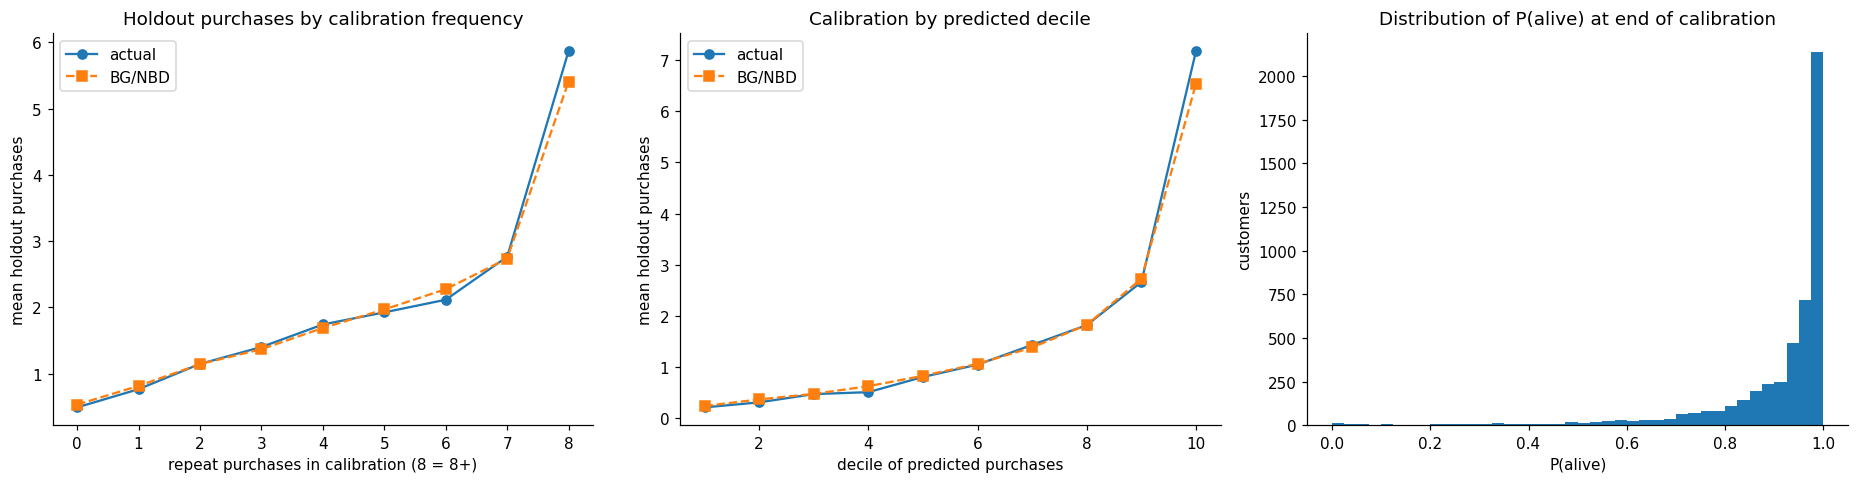

In [21]:
H = window.holdout_weeks
customers["p_alive"] = bgnbd.prob_alive(bg.params, x, t_x, T)
customers["bg_expected_purchases"] = bgnbd.conditional_expected_purchases(bg.params, H, x, t_x, T)

pred, actual = customers["bg_expected_purchases"], customers["holdout_purchases"]
freq_bucket = customers["frequency"].clip(upper=8)
by_freq = pd.DataFrame({"actual": actual, "predicted": pred}).groupby(freq_bucket).mean()
decile = pd.qcut(pred.rank(method="first"), 10, labels=False) + 1
by_decile = pd.DataFrame({"actual": actual, "predicted": pred}).groupby(decile).mean()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].plot(by_freq.index, by_freq["actual"], "o-", label="actual")
axes[0].plot(by_freq.index, by_freq["predicted"], "s--", label="BG/NBD")
axes[0].set(title="Holdout purchases by calibration frequency", xlabel="repeat purchases in calibration (8 = 8+)",
            ylabel="mean holdout purchases")
axes[0].legend()
axes[1].plot(by_decile.index, by_decile["actual"], "o-", label="actual")
axes[1].plot(by_decile.index, by_decile["predicted"], "s--", label="BG/NBD")
axes[1].set(title="Calibration by predicted decile", xlabel="decile of predicted purchases",
            ylabel="mean holdout purchases")
axes[1].legend()
axes[2].hist(customers["p_alive"], bins=40)
axes[2].set(title="Distribution of P(alive) at end of calibration", xlabel="P(alive)", ylabel="customers")
fig.tight_layout()
savefig(fig, "05_bgnbd_validation")

bg_metrics = {"total_predicted": float(pred.sum()), "total_actual": int(actual.sum()),
              "MAE": float(np.mean(np.abs(pred - actual))),
              "RMSE": float(np.sqrt(np.mean((pred - actual) ** 2))),
              "spearman": float(stats.spearmanr(pred, actual).statistic)}
display(pd.Series(bg_metrics).to_frame("BG/NBD holdout fit"))
RESULTS["bgnbd"]["holdout"] = bg_metrics

**Notes.** The BG/NBD model predicts the holdout well, considering it only saw data up to the end of May. In total it expected 7,887 purchase days from June to December, and customers actually made 8,071. That is an underprediction of only about 2%. We expected some underprediction because the holdout includes the pre-Christmas peak, and a model that assumes a steady purchase rate can't see seasonality coming. The effect turned out to be small.

**By calibration frequency (left).** Predicted and actual averages match closely for customers with 0 to 7 repeat purchases. The model is slightly too high for the group with 6 repeat purchases and too low for the most frequent buyers (8 or more), who made 5.9 purchases on average against 5.4 predicted.

**By predicted decile (middle).** The model ranks customers well. Actual purchases rise steadily from the lowest to the highest predicted decile, and the two lines are almost on top of each other for deciles 1 to 9. The only clear gap is in the top decile, where customers bought 7.2 times on average against 6.5 predicted. So the model underestimates its best customers, which fits the idea that heavy buyers, often wholesalers, increase their orders most before Christmas. The Spearman correlation of 0.63 confirms that the ordering of customers is good.

**Error size.** On average a prediction is off by about one purchase day per customer (MAE = 1.08). The RMSE is higher (1.86) because a few heavy buyers have large errors.

**P(alive) (right).** Most customers get a probability of being alive close to 1, and very few fall below 0.5. Part of this is built into the model: in BG/NBD a customer can only leave after a repeat purchase, so the roughly 1,600 one-time buyers always get P(alive) = 1, even though many of them never come back. Together with the low estimated dropout rate, this makes P(alive) optimistic. For deciding which customers are worth targeting, expected purchases are a better guide than P(alive) on its own.

### Testing the Poisson assumption

The BG/NBD model assumes that, while a customer is active, their purchases happen at random moments, like a Poisson process. If that's true, the gaps between one customer's purchases should follow an exponential distribution. A useful property of the exponential is that its **coefficient of variation (CV)**, the standard deviation of the gaps divided by their average, is always 1, no matter how often the customer buys.

So we can check the assumption by looking at each customer's CV of the gaps between purchases:

* **CV close to 1:** buying looks random, as the model assumes.
* **CV well below 1:** buying is more regular than random, for example a shop that restocks every month on a schedule.
* **CV well above 1:** buying is "bursty", with several purchases close together followed by long quiet periods.

There is one catch. For customers with only a few gaps, the CV tends to come out below 1 even when buying really is random. To make a fair comparison, we simulate what each customer's CV would look like if their buying were truly random, using the same number of gaps they actually have, and compare their real CV with that. Gaps are measured in whole days, so the test is only approximate for customers who buy every day or two.

Customers with 3+ gaps: 1,846
Median observed CV: 0.68 vs median CV under Poisson: 0.86
Share below the Poisson 5th percentile (more regular): 22.9% (5% expected if Poisson)
Share above the Poisson 95th percentile (burstier):    3.0% (5% expected if Poisson)


,customers,share_more_regular,share_burstier
segment,,,
S2,4,0.250,0.250
S3,58,0.052,0.069
S4,104,0.125,0.058
S5,147,0.122,0.061
S6,816,0.200,0.021
S7,717,0.314,0.025


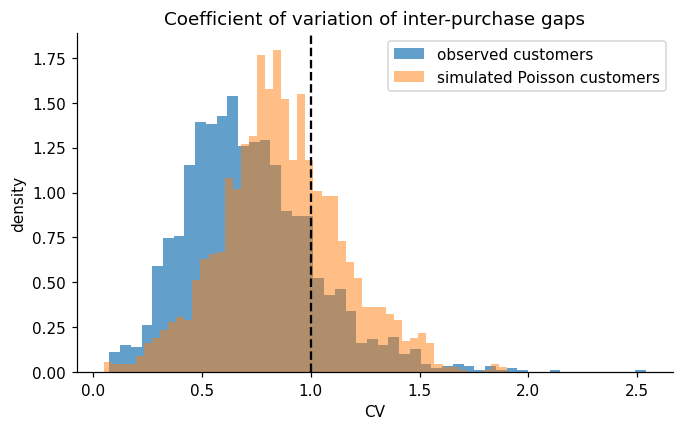

In [23]:
# Gaps between consecutive purchase days for each customer (in weeks; the CV doesn't depend on the unit)
gaps = (calib_days.sort_values(["customer_id", "day"])
        .assign(gap=lambda d: d.groupby("customer_id")["day"].diff().dt.days / 7)
        .dropna(subset=["gap"]))
gap_stats = gaps.groupby("customer_id")["gap"].agg(n_gaps="size", mean="mean", sd="std")
gap_stats = gap_stats[gap_stats["n_gaps"] >= 3].assign(cv=lambda d: d["sd"] / d["mean"])

# Null distribution: CV of the same number of exponential gaps (what Poisson buying would give)
null_q05, null_median, null_q95 = {}, {}, {}
for m in np.unique(gap_stats["n_gaps"]):
    sims = rng.exponential(size=(4000, m))
    cvs = sims.std(axis=1, ddof=1) / sims.mean(axis=1)
    null_q05[m], null_median[m], null_q95[m] = np.quantile(cvs, [0.05, 0.5, 0.95])
gap_stats["null_q05"] = gap_stats["n_gaps"].map(null_q05)
gap_stats["null_median"] = gap_stats["n_gaps"].map(null_median)
gap_stats["null_q95"] = gap_stats["n_gaps"].map(null_q95)
gap_stats["more_regular_than_poisson"] = gap_stats["cv"] < gap_stats["null_q05"]
gap_stats["burstier_than_poisson"] = gap_stats["cv"] > gap_stats["null_q95"]
gap_stats = gap_stats.join(customers["segment"])

share_regular = gap_stats["more_regular_than_poisson"].mean()
share_bursty = gap_stats["burstier_than_poisson"].mean()
print(f"Customers with 3+ gaps: {len(gap_stats):,}")
print(f"Median observed CV: {gap_stats['cv'].median():.2f} vs median CV under Poisson: "
      f"{gap_stats['null_median'].median():.2f}")
print(f"Share below the Poisson 5th percentile (more regular): {share_regular:.1%} (5% expected if Poisson)")
print(f"Share above the Poisson 95th percentile (burstier):    {share_bursty:.1%} (5% expected if Poisson)")
display(gap_stats.groupby("segment")[["more_regular_than_poisson", "burstier_than_poisson"]]
        .agg(["size", "mean"]).iloc[:, [0, 1, 3]]
        .set_axis(["customers", "share_more_regular", "share_burstier"], axis=1).round(3))

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(gap_stats["cv"], bins=50, alpha=0.7, density=True, label="observed customers")
# One simulated Poisson customer for each real customer, with the same number of gaps
null_draw = np.array([(lambda s: s.std(ddof=1) / s.mean())(rng.exponential(size=m))
                      for m in gap_stats["n_gaps"]])
ax.hist(null_draw, bins=50, alpha=0.5, density=True, label="simulated Poisson customers")
ax.axvline(1, color="k", ls="--")
ax.set(title="Coefficient of variation of inter-purchase gaps", xlabel="CV", ylabel="density")
ax.legend()
savefig(fig, "06_poisson_check")
RESULTS["poisson_check"] = {"customers_tested": int(len(gap_stats)),
                            "share_more_regular_than_poisson": float(share_regular),
                            "share_burstier_than_poisson": float(share_bursty)}

**Notes.** The Poisson assumption doesn't hold well for frequent buyers. Among the 1,846 customers with at least three gaps between purchases, the median CV is 0.68, while truly random buying with the same number of gaps would give about 0.86. In the histogram, the observed customers (blue) are clearly shifted left of the simulated Poisson customers (orange). 22.9% of customers are significantly more regular than random, more than four times the 5% we would expect by chance. Bursty buying is rare: only 3.0% are significantly burstier, which is actually below the 5% expected. So the departure from Poisson goes one way: many customers buy on a fairly regular schedule, which fits shops that restock at regular intervals.

**By segment.** Regular buying is concentrated in the most valuable segments: 31% of customers in S7 and 20% in S6 are more regular than random, compared with about 12% in S4 and S5 and 5% in S3. S1 doesn't appear because none of its customers have three or more gaps, and S2 has only four customers, so its shares shouldn't be read into. The bursty shares in S3 to S5 (about 6–7%) are close to the 5% expected by chance.

**What this means for the BG/NBD model.** The model still predicted total and average holdout purchases well, because a regular buyer and a random buyer with the same rate make the same number of purchases on average. Where the assumption matters is in the details. For regular buyers, the model is too uncertain about how many purchases they'll make. It is also slow to notice when they leave: a regular customer who misses their usual reorder is a stronger warning sign than the model realises, because it treats long gaps as normal under random buying. A model that allows for more regular timing would capture this better, but BG/NBD remains a reasonable working model for predicting overall purchase levels.

### A Markov chain over recency states

As a second, simpler model of buying, we follow customers month by month. Each month, a customer is in a "state" that records how many months have passed since the last month they bought anything: 0 (bought this month), 1, 2, … up to 5, with 6 meaning six months or more.

From one month to the next, only two things can happen:

* **The customer buys:** they move back to state 0.
* **The customer doesn't buy:** they move one step further, from state $k$ to $k + 1$ (customers already in state 6+ stay there).

This is a Markov chain: the chance of buying next month depends only on the current state, not on the full purchase history. We estimate each transition probability from the data as the share of customers who actually made that move. For example, if 1,000 customer-months start in state 2 and 150 of them lead to a purchase, the estimated probability of moving from state 2 to state 0 is 150 / 1,000 = 0.15. This simple proportion is the maximum-likelihood estimate.

The most useful part of the result is the first column of the transition matrix (moves to state 0). It gives the **monthly repurchase rate** for each state: the chance that a customer buys next month, given how long it has been since they last bought. If this rate drops steadily as months pass, a long gap since the last purchase is a strong sign that a customer is drifting away.

Transitions used: 54,862


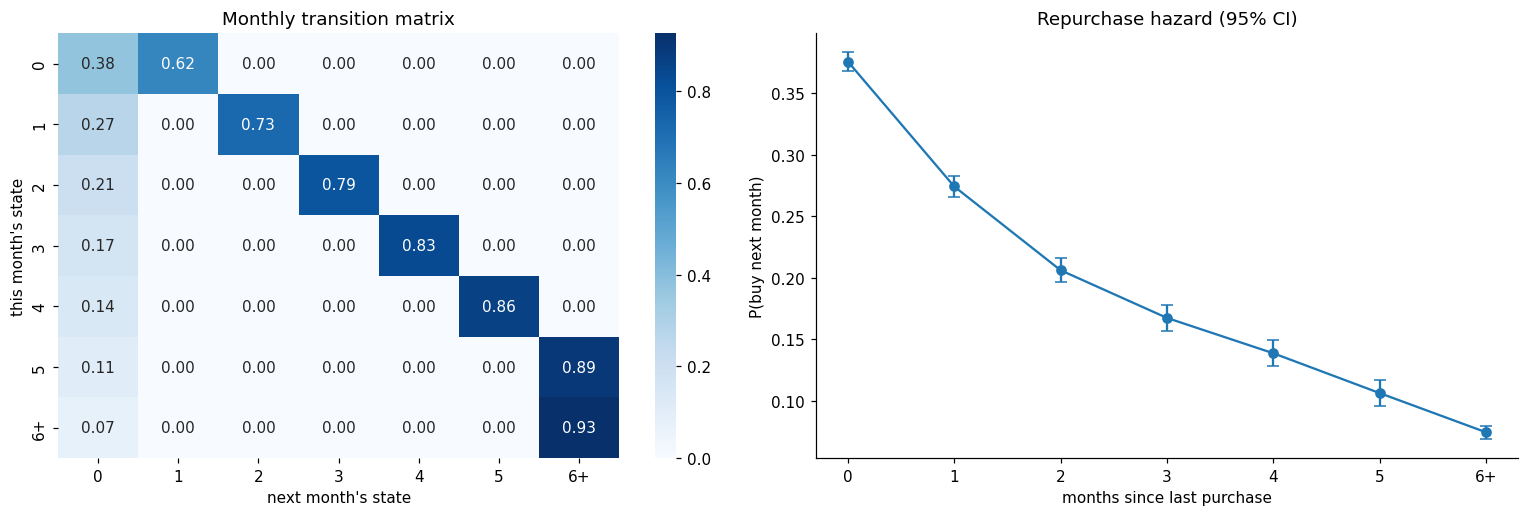

In [25]:
class markov:
    """Discrete-time Markov chain over monthly recency states (0, 1, ..., MAX_RECENCY-1, MAX_RECENCY+)."""

    @staticmethod
    def state_labels(max_recency):
        return [str(k) for k in range(max_recency)] + [f"{max_recency}+"]

    @staticmethod
    def build_recency_panel(calib_days, last_month, max_recency):
        """One row per customer-month, from the customer's first purchase month to last_month.
        state = months since the last month with a purchase (0 = bought this month), capped at max_recency."""
        months = calib_days.assign(month=calib_days["day"].dt.to_period("M"))
        bought = months[["customer_id", "month"]].drop_duplicates()
        bought = bought[bought["month"] <= last_month]
        bought["m"] = bought["month"].apply(lambda p: p.ordinal)

        first = bought.groupby("customer_id")["m"].min()
        n_months = last_month.ordinal - first + 1
        panel = pd.DataFrame({"customer_id": np.repeat(first.index.to_numpy(), n_months.to_numpy())})
        panel["m"] = np.repeat(first.to_numpy(), n_months.to_numpy()) + panel.groupby("customer_id").cumcount()
        panel = panel.merge(bought[["customer_id", "m"]].assign(bought=True), on=["customer_id", "m"], how="left")
        panel["bought"] = panel["bought"].fillna(False).astype(bool)

        last_buy = panel["m"].where(panel["bought"]).groupby(panel["customer_id"]).ffill()
        panel["state"] = (panel["m"] - last_buy).clip(upper=max_recency).astype(int)
        return panel[["customer_id", "m", "bought", "state"]]

    @staticmethod
    def transitions(panel):
        """Pairs of (this month's state, next month's state) for each customer."""
        nxt = panel.groupby("customer_id")["state"].shift(-1)
        return pd.DataFrame({"from_state": panel["state"], "to_state": nxt}).dropna().astype(int)

    @staticmethod
    def estimate_transition_matrix(trans, K):
        """Maximum-likelihood transition matrix (row proportions) with binomial standard errors."""
        counts = np.zeros((K, K))
        np.add.at(counts, (trans["from_state"].to_numpy(), trans["to_state"].to_numpy()), 1)
        n_i = counts.sum(axis=1, keepdims=True)
        P = np.divide(counts, n_i, out=np.zeros_like(counts), where=n_i > 0)
        P_se = np.sqrt(np.divide(P * (1 - P), n_i, out=np.zeros_like(P), where=n_i > 0))
        return P, P_se, counts


# Last full month of the calibration period (May 2011 when CALIBRATION_END = 1 June 2011)
last_calibration_month = (window.calibration_end - pd.Timedelta(days=1)).to_period("M")

LABELS = markov.state_labels(MAX_RECENCY)
K = len(LABELS)
panel = markov.build_recency_panel(calib_days, last_calibration_month, MAX_RECENCY)
trans = markov.transitions(panel)
P, P_se, counts = markov.estimate_transition_matrix(trans, K)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.heatmap(pd.DataFrame(P, index=LABELS, columns=LABELS), annot=True, fmt=".2f", cmap="Blues", ax=axes[0])
axes[0].set(title="Monthly transition matrix", xlabel="next month's state", ylabel="this month's state")
axes[1].errorbar(range(K), P[:, 0], yerr=1.96 * P_se[:, 0], fmt="o-", capsize=4)
axes[1].set_xticks(range(K), LABELS)
axes[1].set(title="Repurchase hazard (95% CI)", xlabel="months since last purchase",
            ylabel="P(buy next month)")
fig.tight_layout()
savefig(fig, "07_markov_chain")
print(f"Transitions used: {int(counts.sum()):,}")

**Notes.** The chain is estimated from 54,862 monthly transitions, so the probabilities are very precise: the 95% intervals on the right are barely wider than the dots.

The transition matrix has the expected shape. In each row a customer either buys and returns to state 0 (first column) or moves one step further along the diagonal. Customers in state 6+ mostly stay there (93% per month), so this state behaves almost like a "lapsed" state that is hard to leave.

**Repurchase rate.** The chance of buying next month falls steadily the longer it has been since the last purchase. It drops from 38% for customers who bought this month to 27% after one month without buying, 21% after two, and about 7% after six months or more, a fall of more than five times. Each step is clearly different from the next, so recency is a strong warning signal: every extra quiet month makes a customer noticeably less likely to come back. This matches the CCA, where recency was one of the strongest links to future buying, and the idea behind BG/NBD that a long silence suggests a customer has left.

One caution in reading this curve: it doesn't necessarily mean each individual customer becomes less likely to buy as time passes. Part of the decline comes from sorting. Frequent buyers rarely go long without buying, so the high recency states fill up mainly with occasional buyers and customers who have already left. BG/NBD explains the same pattern through differences between customers plus dropout. Even so, about 7% of long-lapsed customers still buy each month, so they are not all lost for good.

### Do the transition probabilities change over time?

Our Markov chain uses one transition matrix for the whole calibration period. That assumes the chance of buying next month, at each recency state, stays the same over time (the chain is "time-homogeneous"). If customers behave differently at different times of year, or if behaviour shifted between 2010 and 2011, a single matrix would hide that.

To check, we split the transitions into groups, estimate a separate matrix for each group, and compare them with the single pooled matrix using a **likelihood-ratio test** (also called the $G^2$ test). The test asks whether the separate matrices fit the data meaningfully better than one shared matrix. A small p-value means the probabilities really do differ between groups.

When counting degrees of freedom, we only count transitions that can actually happen. From each state, a customer can only buy (move to 0) or not buy (move one step on), so most cells in each row are always zero by design. Each row therefore has just one free probability per group.

We test two groupings:

* **First half vs. second half of the calibration period:** has buying behaviour changed over time?
* **Q4 (October to December) vs. the rest of the year:** is there a seasonal effect, such as more repurchases before Christmas?

,G2,df,p_value
first vs second half,25.8013,7.0,0.0005
Q4 vs Q1-Q3,196.4057,7.0,0.0000


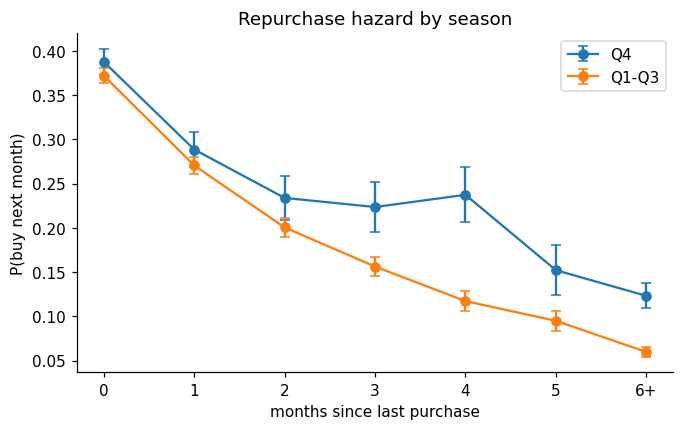

In [26]:
def homogeneity_lr_test(trans, groups, K):
    """Likelihood-ratio (G^2) test: one pooled transition matrix vs. a separate matrix per group.
    Degrees of freedom count only transitions that can actually happen (structural zeros are skipped)."""
    groups = np.asarray(groups)
    pooled, _, pooled_counts = markov.estimate_transition_matrix(trans, K)
    G2, df = 0.0, 0
    group_counts = [markov.estimate_transition_matrix(trans[groups == g], K)[2] for g in np.unique(groups)]
    for i in range(K):
        possible = pooled_counts[i] > 0                            # transitions seen from state i
        rows_with_data = [c[i] for c in group_counts if c[i].sum() > 0]
        df += (len(rows_with_data) - 1) * (possible.sum() - 1)
        for row in rows_with_data:
            p_g = row / row.sum()
            ok = row > 0
            G2 += 2 * np.sum(row[ok] * np.log(p_g[ok] / pooled[i, ok]))
    return {"G2": G2, "df": df, "p_value": stats.chi2.sf(G2, df) if df > 0 else np.nan}

markov.homogeneity_lr_test = staticmethod(homogeneity_lr_test)

# Month in which each transition's outcome happens (buy or not), i.e. the "next" month
next_m = panel.loc[trans.index, "m"].to_numpy() + 1
trans = trans.assign(month=pd.to_datetime(pd.DataFrame({"year": 1970 + next_m // 12,
                                                        "month": next_m % 12 + 1, "day": 1}))
                             .dt.to_period("M").to_numpy())

months_sorted = np.sort(trans["month"].unique())
midpoint = months_sorted[len(months_sorted) // 2]
half = np.where(trans["month"] < midpoint, "first half", "second half")
quarter = np.where(trans["month"].map(lambda p: p.quarter) == 4, "Q4", "Q1-Q3")

homog = pd.DataFrame({name: markov.homogeneity_lr_test(trans, grp, K)
                      for name, grp in {"first vs second half": half, "Q4 vs Q1-Q3": quarter}.items()}).T
display(homog[["G2", "df", "p_value"]].astype(float).round(4))

fig, ax = plt.subplots(figsize=(7, 4))
for lab in ["Q4", "Q1-Q3"]:
    P_g, se_g, _ = markov.estimate_transition_matrix(trans[quarter == lab], K)
    ax.errorbar(range(K), P_g[:, 0], yerr=1.96 * se_g[:, 0], fmt="o-", capsize=3, label=lab)
ax.set_xticks(range(K), LABELS)
ax.set(title="Repurchase hazard by season", xlabel="months since last purchase", ylabel="P(buy next month)")
ax.legend()
savefig(fig, "08_markov_seasonality")
RESULTS["markov_homogeneity"] = {k: {"G2": float(v["G2"]), "df": int(v["df"]), "p": float(v["p_value"])}
                                 for k, v in homog.iterrows()}

**Notes.** Both tests reject the idea that one transition matrix fits all months, but the two differences are very different in size.

**Season.** The seasonal difference is large: $G^2 = 196$ on 7 degrees of freedom, p < 0.001. In the chart, customers are more likely to buy in Q4 at every recency state, and the gap grows the longer a customer has been away. For customers who bought last month, the Q4 rate is only slightly higher (39% vs 37%). For customers who have been quiet for four months, it is twice as high (24% vs 12%), and for those away six months or more it also doubles (12% vs 6%). So the Christmas season mainly brings back lapsed customers, not just regulars buying a little more.

**Over time.** The first-half vs second-half difference is also significant ($G^2 = 25.8$, p < 0.001), but it is about eight times smaller. With 54,862 transitions, even small differences come out significant. Part of it is probably seasonal too: the second half of the calibration period contains October to December 2010, while the first half contains no Q4 months at all.

**What this means.** The Markov chain, like BG/NBD, assumes buying behaviour doesn't change with the calendar, and here that assumption clearly fails for Q4. This helps explain why BG/NBD slightly underpredicted the holdout, which includes the 2011 Christmas season. For the retention team, the timing matters: lapsed customers are about twice as likely to return in Q4, so the months just before Christmas are the best moment to try to win them back.

### Long-run behaviour and holdout forecasts

Once we have the transition matrix, we can use it to describe where customers end up over time and to make forecasts for the holdout period. We look at three things:

* **Long-run share of customers in each state (stationary distribution).** If the chain kept running for a long time, the share of customer-months in each recency state would settle down to a fixed pattern, written $\pi$. It satisfies $\pi = \pi P$, meaning one more month of transitions leaves the shares unchanged. It tells us, for example, what share of the customer base we should expect to be lapsed (6+ months without buying) at any given time.

* **How long until a customer lapses (mean first-passage time).** For each starting state, we calculate the expected number of months until a customer first reaches six months without buying. To do this, we treat 6+ as a state the customer can't leave and work out the expected time to get there from every other state. The standard formula uses the fundamental matrix $N = (I - Q)^{-1}$, where $Q$ is the part of the transition matrix covering the states before 6+; the expected time to lapse from each state is $N\mathbf{1}$, the row sums of $N$.

* **Holdout forecasts.** Starting from each customer's state at the end of May 2011, we run the chain forward month by month through the holdout. This gives, for every customer, the expected number of months in which they buy, and the probability that they buy at least once.

Two things to keep in mind when comparing these forecasts with BG/NBD. First, the chain counts purchase *months*, while BG/NBD counts purchase *days*, so a customer who buys several times in one month counts once here. Second, these forecasts use the single pooled matrix, which ignores the Q4 effect we just found, so we expect them to underpredict buying in the holdout, which includes the run-up to Christmas.

In [27]:
def stationary_distribution(P):
    """Long-run share of time in each state: solves pi = pi P with sum(pi) = 1."""
    K = len(P)
    A = np.vstack([(P - np.eye(K)).T, np.ones(K)])
    rhs = np.r_[np.zeros(K), 1.0]
    return np.linalg.lstsq(A, rhs, rcond=None)[0]

def expected_steps_to(P, target):
    """Mean first-passage time to `target` from every state, using the fundamental matrix N = (I - Q)^-1."""
    K = len(P)
    others = [i for i in range(K) if i != target]
    Q = P[np.ix_(others, others)]                    # transitions among the states before `target`
    N = np.linalg.inv(np.eye(len(others)) - Q)
    steps = np.zeros(K)
    steps[others] = N @ np.ones(len(others))
    return steps

def forecast(P, start_state, n_months):
    """Run the chain forward n_months from each customer's state.
    Returns expected number of purchase months and P(at least one purchase)."""
    K = len(P)
    no_buy = P.copy()
    no_buy[:, 0] = 0                                  # paths that never return to state 0 (never buy)
    exp_by_state, p_any_by_state = np.zeros(K), np.zeros(K)
    for s in range(K):
        dist, dist_none = np.eye(K)[s], np.eye(K)[s]
        for _ in range(n_months):
            dist = dist @ P
            dist_none = dist_none @ no_buy
            exp_by_state[s] += dist[0]                # chance of buying in this month
        p_any_by_state[s] = 1 - dist_none.sum()
    start = np.asarray(start_state, dtype=int)
    return exp_by_state[start], p_any_by_state[start]

markov.stationary_distribution = staticmethod(stationary_distribution)
markov.expected_steps_to = staticmethod(expected_steps_to)
markov.forecast = staticmethod(forecast)

# Holdout length in calendar months (June to December 2011 = 7; December is partial)
first_holdout_month = window.calibration_end.to_period("M")
last_holdout_month = (window.holdout_end - pd.Timedelta(days=1)).to_period("M")
holdout_months = last_holdout_month.ordinal - first_holdout_month.ordinal + 1

# Actual number of holdout months with at least one purchase, per customer
_hold = purchases[(purchases["invoice_date"] >= window.calibration_end)
                  & (purchases["invoice_date"] < window.holdout_end)]
customers["holdout_active_months"] = (_hold.assign(month=_hold["invoice_date"].dt.to_period("M"))
                                      .groupby("customer_id")["month"].nunique()
                                      .reindex(customers.index, fill_value=0).astype(int))

pi = markov.stationary_distribution(P)
steps_to_dormant = markov.expected_steps_to(P, target=K - 1)
display(pd.DataFrame({"stationary_share": pi, "months_until_6+_without_buying": steps_to_dormant},
                     index=LABELS).round(3))

end_state = panel.groupby("customer_id")["state"].last().reindex(customers.index)
exp_months, p_any = markov.forecast(P, end_state, holdout_months)
customers["markov_expected_months"] = exp_months
customers["markov_p_any"] = p_any

active = customers["holdout_active"]
model_compare = pd.DataFrame({
    "AUC: any holdout purchase": [roc_auc_score(active, customers["bg_expected_purchases"]),
                                  roc_auc_score(active, customers["markov_p_any"])],
    "Spearman with holdout purchase count": [stats.spearmanr(customers["bg_expected_purchases"],
                                                             customers["holdout_purchases"]).statistic,
                                             stats.spearmanr(customers["markov_expected_months"],
                                                             customers["holdout_purchases"]).statistic],
}, index=["BG/NBD", "Markov chain"])
display(model_compare.round(3))
print(f"Markov: predicted active months {exp_months.sum():,.0f} vs actual "
      f"{customers['holdout_active_months'].sum():,} (holdout spans {holdout_months} calendar months; "
      "the last one is partial)")
RESULTS["stochastic_comparison"] = model_compare.round(4).to_dict()

,stationary_share,months_until_6+_without_buying
0,0.164,12.984
1,0.102,11.382
2,0.074,9.399
3,0.059,7.209
4,0.049,4.847
5,0.042,2.378
6+,0.509,0.000


,AUC: any holdout purchase,Spearman with holdout purchase count
BG/NBD,0.808,0.629
Markov chain,0.740,0.525


Markov: predicted active months 5,897 vs actual 6,155 (holdout spans 7 calendar months; the last one is partial)


**Notes.**

**Long-run picture.** If buying continued as it did in calibration, about half of all customer-months (51%) would be spent in the lapsed state, six or more months without buying. Only 16% would be months with a purchase. So at any given time, around half of the customer base is dormant, which is consistent with the many one-time and occasional buyers we saw at the start.

**Time until a customer lapses.** A customer who has just bought takes about 13 months on average to reach six months in a row without buying. The quickest possible route is 6 months, so a typical customer buys again a few more times before finally going quiet. The expected time shrinks quickly as recency grows: about 7 months from state 3 and 2.4 months from state 5. A customer who has already gone 3 to 5 months without buying is therefore close to lapsing, which makes this a natural window for a win-back offer.

**Holdout forecasts.** The chain predicts 5,897 purchase months in the holdout against 6,155 actual, an underprediction of about 4%. This is in line with the Q4 effect we found: the chain uses one matrix for the whole year, so it misses the extra buying before Christmas. BG/NBD underpredicted by a smaller margin (2%), though it counts purchase days rather than months.

**Comparing the two models.** BG/NBD is clearly better at telling customers apart. It separates customers who bought again in the holdout from those who didn't with an AUC of 0.81, against 0.74 for the Markov chain, and it ranks customers by how much they will buy more accurately (Spearman 0.63 vs 0.53). This is expected: the chain only knows how many months it has been since a customer last bought, so every customer in the same state gets the same forecast. BG/NBD also uses how often each customer bought and how long we've observed them. The Markov chain is still useful as a simple, easy-to-explain model, and it confirms the same story: recency matters a lot, and seasonality pushes actual buying above what either model expects.

## Linear models

Now we try to predict how much each customer will spend in the holdout. This is tricky for an ordinary linear regression. Many customers spend nothing because they never come back, and among those who do return, spending is very uneven: most spend modest amounts while a few spend a great deal. A single straight-line model can't handle both of those features well.

So we use a **two-part model**, which splits the question in two:

1. **Will the customer buy at all?** A logistic regression (a GLM for yes/no outcomes) predicts the probability that a customer makes any purchase in the holdout.
2. **If they buy, how much will they spend?** A second model predicts spend, using only the customers who did buy.

A customer's expected spend is then the probability of buying multiplied by the expected spend if they buy.

**Predictors.** All predictors come from the calibration period. Recency and tenure are converted from weeks to months so the coefficients are easier to read ("per extra month since the last purchase").

**Leaving out redundant features.** We drop `log_items_per_order` for the same reason as before: it is exactly `log_aov` minus `log_avg_price`, so it adds no new information. The first column of the VIF table below shows what happens if we include it: the variance inflation factors become infinite, meaning the model can't separate the effects of these three features at all.

`log_orders` and `log_products` are also strongly related, since customers who buy more often tend to buy a wider range of products. This makes their individual coefficients less certain (larger standard errors), but it doesn't harm the model's predictions, so we keep both.

In [28]:
customers["recency_months"] = customers["recency_weeks"] / (52 / 12)
customers["tenure_months"] = customers["tenure_weeks"] / (52 / 12)
PREDICTORS = ["recency_months", "tenure_months", "log_orders", "log_aov", "log_products",
              "log_avg_price", "return_rate", "q4_share", "is_uk"]
RHS = " + ".join(PREDICTORS)

def vif_table(cols):
    Xv = sm.add_constant(customers[cols].astype(float))   # is_uk is True/False, so convert to 0/1
    return pd.Series([variance_inflation_factor(Xv.to_numpy(), i) for i in range(1, Xv.shape[1])], index=cols)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")   # the first table is rank-deficient on purpose
    vifs = pd.DataFrame({"VIF (with log_items_per_order)": vif_table(PREDICTORS + ["log_items_per_order"]),
                         "VIF (model)": vif_table(PREDICTORS)}).reindex(PREDICTORS + ["log_items_per_order"])
display(vifs.mask(vifs > 1e6, np.inf).round(1))

,VIF (with log_items_per_order),VIF (model)
recency_months,2.9,2.9
tenure_months,2.9,2.9
log_orders,4.5,4.5
log_aov,inf,1.4
log_products,2.3,2.3
log_avg_price,inf,1.0
return_rate,1.0,1.0
q4_share,1.0,1.0
is_uk,1.0,1.0
log_items_per_order,inf,NaN


**Notes.** The first column confirms the problem with `log_items_per_order`. When it is included, it and the two features it is built from (`log_aov` and `log_avg_price`) all get infinite VIFs, because any one of them can be calculated exactly from the other two. Once it is removed, those VIFs drop to 1.4 and 1.0, so the remaining features carry separate information.

In the final model, every VIF is below 5, a common rule-of-thumb threshold, so multicollinearity is not a serious problem. The highest is `log_orders` (4.5). Its standard error is about twice as large as it would be if it were unrelated to the other predictors (√4.5 ≈ 2.1), mainly because frequent buyers also tend to buy more distinct products and to have bought recently. `recency_months` and `tenure_months` are moderately related (2.9 each): a customer's recency can never be longer than their tenure, and for one-time buyers the two are equal. Return rate, Q4 share and UK location are essentially unrelated to everything else (VIF ≈ 1).

## Part one: who buys again? (logistic GLM)

In [29]:
# The response must be 0/1: with a True/False column, statsmodels models P(False) and every effect flips sign
logit_data = customers.assign(bought=customers["holdout_active"].astype(int))
logit = smf.glm(f"bought ~ {RHS}", data=logit_data, family=sm.families.Binomial()).fit()

or_table = pd.DataFrame({"odds_ratio": np.exp(logit.params),
                         "ci_lower": np.exp(logit.conf_int()[0]), "ci_upper": np.exp(logit.conf_int()[1]),
                         "p_value": logit.pvalues}).drop(index="Intercept")
display(or_table.round(3))
print(f"In-sample AUC: {roc_auc_score(customers['holdout_active'], logit.fittedvalues):.3f}")
RESULTS["logit_odds_ratios"] = or_table["odds_ratio"].round(4).to_dict()

,odds_ratio,ci_lower,ci_upper,p_value
is_uk[T.True],1.017,0.797,1.297,0.893
recency_months,0.873,0.852,0.895,0.000
tenure_months,0.969,0.948,0.991,0.006
log_orders,2.503,2.128,2.943,0.000
log_aov,1.236,1.112,1.374,0.000
log_products,1.124,1.037,1.219,0.005
log_avg_price,0.809,0.704,0.929,0.003
return_rate,0.827,0.281,2.434,0.731
q4_share,1.100,0.910,1.330,0.326


In-sample AUC: 0.810


**Notes.** The logistic model confirms what the CCA and BG/NBD suggested: how often and how recently a customer bought are by far the strongest signals of whether they come back.

**Recency.** Each extra month since the last purchase lowers the odds of buying in the holdout by about 13% (odds ratio 0.87). The effect builds up quickly: a customer who has been quiet for six months has less than half the odds (0.87⁶ ≈ 0.44) of an otherwise similar customer who just bought.

**Purchase frequency.** `log_orders` has the largest effect. Because it is on a log scale, its odds ratio of 2.50 is per 2.7-fold increase in purchase occasions. It is easier to read as: doubling a customer's number of purchase occasions multiplies their odds of returning by about 1.9.

**Tenure.** With frequency and recency held fixed, each extra month of tenure lowers the odds slightly (about 3% per month). This makes sense: two customers with the same number of purchases are not equally active if one took much longer to make them. The one with longer tenure buys at a slower rate.

**Spending style.** Doubling spend per occasion raises the odds by about 16%, and doubling the number of distinct products raises them by about 8%. Doubling the average unit price *lowers* them by about 14%. For the same spend per visit, customers who buy cheaper items in larger quantities, which is typical of wholesalers and resellers, are more likely to come back than those buying a few expensive items.

**No clear effect.** Return rate, Q4 share and UK location are not significant (p > 0.3). The return-rate interval is especially wide (0.28 to 2.43), because most customers return very little, so there is not enough variation to measure its effect precisely. This matches the CCA, where these three features were also unrelated to future buying.

### how much do returning customers spend?

Now we model how much customers spend in the holdout, using only the customers who did buy. Spend is very skewed, so we try two models and one correction:

* **Linear regression on log spend.** Taking the log of spend makes its distribution much more even, so an ordinary linear regression (OLS) fits better. We then check whether the model's assumptions hold. The Breusch–Pagan test checks whether the size of the errors changes with the predictors (heteroskedasticity). Because that often happens with spending data, we also report robust (HC3) standard errors, which stay valid either way. Residual plots show whether the errors look random, and Cook's distance flags individual customers who have an unusually large influence on the results.

* **Gamma GLM with a log link.** This model predicts average spend directly, on the original £ scale, rather than log spend. It also assumes that customers with higher expected spend vary more in how much they spend, which is usually true for money amounts.

* **Correcting the log model's predictions (Duan's smearing).** To turn a log-spend prediction back into pounds, it's tempting to just take $e^{\hat\mu}$. But that gives the *median* spend, not the *average*, and for skewed data the average is higher, so this underestimates spend. Duan's smearing estimator fixes this by multiplying every prediction by the average of $e^{\text{residual}}$ across customers. This scales the predictions up to the right average level, without assuming the errors follow a particular distribution.

Breusch–Pagan LM = 47.8, p = 2.76e-07;  R² = 0.515;  n = 2,592


,coef,SE_classical,SE_HC3,p_HC3,SE_ratio
Intercept,1.2481,0.1714,0.2019,0.0000,1.1780
is_uk[T.True],-0.0803,0.0608,0.0611,0.1889,1.0055
recency_months,0.0174,0.0069,0.0076,0.0224,1.1073
tenure_months,-0.0562,0.0051,0.0053,0.0000,1.0492
log_orders,0.8108,0.0352,0.0380,0.0000,1.0793
log_aov,0.8972,0.0270,0.0321,0.0000,1.1879
log_products,-0.0871,0.0201,0.0223,0.0001,1.1066
log_avg_price,-0.0529,0.0397,0.0448,0.2371,1.1271
return_rate,0.7594,0.2952,0.5696,0.1825,1.9295
q4_share,-0.0581,0.0587,0.0586,0.3216,0.9988


,cooks_d,holdout_spend,calib_spend,n_purchase_days,country,segment
customer_id,,,,,,
14842,0.265070,2501.94,15.00,1,United Kingdom,S4
15158,0.024010,401.40,39.62,1,United Kingdom,S4
16801,0.022310,140.85,701.48,2,United Kingdom,S4
17557,0.020743,541.46,34.00,1,United Kingdom,S2
17940,0.018483,644.50,27745.08,8,United Kingdom,S4
12875,0.017741,49.47,1307.52,4,United Kingdom,S4
17408,0.017707,32.65,132.24,2,United Kingdom,S4
17040,0.016808,449.73,13.52,1,United Kingdom,S1


,all buyers,without Cook's D > 4/n (151)
Intercept,1.2481,1.0300
is_uk[T.True],-0.0803,-0.0701
recency_months,0.0174,0.0120
tenure_months,-0.0562,-0.0541
log_orders,0.8108,0.8198
log_aov,0.8972,0.9381
log_products,-0.0871,-0.0846
log_avg_price,-0.0529,-0.1137
return_rate,0.7594,0.4503
q4_share,-0.0581,-0.0676


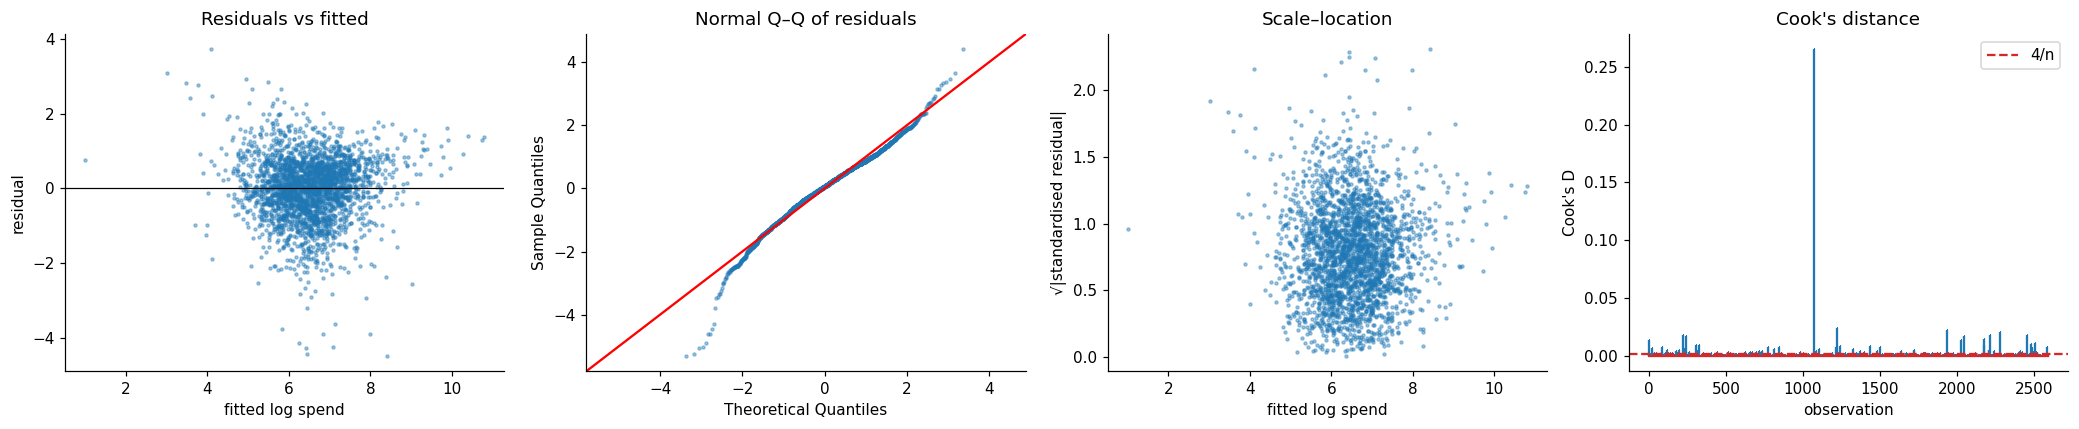

In [30]:
buyers = customers[customers["holdout_active"]].copy()
buyers["log_spend"] = np.log(buyers["holdout_spend"])

ols = smf.ols(f"log_spend ~ {RHS}", data=buyers).fit()
ols_hc3 = smf.ols(f"log_spend ~ {RHS}", data=buyers).fit(cov_type="HC3")
bp_stat, bp_p, _, _ = het_breuschpagan(ols.resid, ols.model.exog)
print(f"Breusch–Pagan LM = {bp_stat:.1f}, p = {bp_p:.3g};  R² = {ols.rsquared:.3f};  n = {int(ols.nobs):,}")

coef_table = pd.DataFrame({"coef": ols.params, "SE_classical": ols.bse, "SE_HC3": ols_hc3.bse,
                           "p_HC3": ols_hc3.pvalues})
coef_table["SE_ratio"] = coef_table["SE_HC3"] / coef_table["SE_classical"]
display(coef_table.round(4))

influence = ols.get_influence()
cooks = influence.cooks_distance[0]
cutoff = 4 / ols.nobs
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
axes[0].scatter(ols.fittedvalues, ols.resid, s=4, alpha=0.4)
axes[0].axhline(0, color="k", lw=0.8)
axes[0].set(title="Residuals vs fitted", xlabel="fitted log spend", ylabel="residual")
sm.qqplot(ols.resid, line="45", fit=True, ax=axes[1], markersize=2, alpha=0.4)
axes[1].set_title("Normal Q–Q of residuals")
axes[2].scatter(ols.fittedvalues, np.sqrt(np.abs(influence.resid_studentized_internal)), s=4, alpha=0.4)
axes[2].set(title="Scale–location", xlabel="fitted log spend", ylabel="√|standardised residual|")
axes[3].stem(cooks, markerfmt=",")
axes[3].axhline(cutoff, color="C3", ls="--", label="4/n")
axes[3].set(title="Cook's distance", xlabel="observation", ylabel="Cook's D")
axes[3].legend()
fig.tight_layout()
savefig(fig, "09_ols_diagnostics")

influential = buyers.assign(cooks_d=cooks).nlargest(8, "cooks_d")
display(influential[["cooks_d", "holdout_spend", "calib_spend", "n_purchase_days", "country", "segment"]])
n_infl = int((cooks > cutoff).sum())
ols_trim = smf.ols(f"log_spend ~ {RHS}", data=buyers[cooks <= cutoff]).fit(cov_type="HC3")
display(pd.DataFrame({"all buyers": ols_hc3.params,
                      f"without Cook's D > 4/n ({n_infl})": ols_trim.params}).round(4))
RESULTS["ols"] = {"r2": float(ols.rsquared), "breusch_pagan_p": float(bp_p), "n_influential": n_infl}

**Notes.** Among the 2,592 customers who bought in the holdout, the model explains about half of the variation in log spend (R² = 0.52). That is good for customer-level spending data.

**What drives spend.** Because both spend and the main predictors are on a log scale, the coefficients can be read as percentage effects:

* **Spend per occasion** (`log_aov`, 0.90) is the strongest driver. Customers who spent twice as much per visit in calibration spend about 86% more in the holdout (2^0.90 ≈ 1.86), so past order size carries over almost one-for-one.
* **Number of purchase occasions** (`log_orders`, 0.81): doubling past purchase occasions goes with about 75% more holdout spend.
* **Tenure** (−0.056 per month): each extra month of tenure lowers expected spend by about 5%, holding the number of purchases fixed. As in the logistic model, a customer who took longer to make the same number of purchases is a slower buyer.
* **Number of products** (−0.087): for the same frequency and order size, buying a wider range of products goes with slightly lower spend (about 6% less per doubling). This effect is small and partly reflects the overlap with `log_orders`.
* **Recency** (+0.017 per month): among customers who do come back, a longer gap since the last purchase goes with slightly *higher* spend, about 2% per month. One explanation is that customers who return after a long break place a bigger catch-up order. The effect is small and only just significant (p = 0.02).
* Average unit price, return rate, Q4 share and UK location have no significant effect.

**Heteroskedasticity.** The Breusch–Pagan test is clearly significant (p < 0.001), so the spread of the errors is not constant. Switching to robust (HC3) standard errors changes little: most standard errors grow by only 1–19%, and every conclusion above stays the same. The exception is return rate, whose standard error almost doubles (ratio 1.93). It would look significant with classical standard errors (p ≈ 0.01), but it is not once we allow for heteroskedasticity (p = 0.18).

**Influential customers.** 151 customers (about 6%) have a Cook's distance above the 4/n cut-off. One stands out: customer 14842 has a Cook's distance about ten times larger than anyone else. They spent only £15 on a single day in calibration, then £2,502 in the holdout. Most of the other influential customers are similar surprises: one-time buyers with small first orders who later spent hundreds of pounds, or the reverse, like customer 17940, who spent £27,745 in calibration but only £645 in the holdout. These look like real, unpredictable customers rather than data errors, so we keep them in the model.

Refitting without these 151 customers barely changes the main results: the coefficients for `log_orders`, `log_aov`, `log_products` and tenure move by less than 5%. The predictors that move most are return rate (0.76 to 0.45) and average unit price (−0.05 to −0.11), both of which were not significant to begin with. The model's conclusions are therefore not driven by a handful of unusual customers.

**Notes.** The diagnostic plots show that the log-spend model is reasonable overall, with two weaknesses: heavy tails and a little uneven spread.

**Residuals vs fitted.** The residuals are centred on zero across the whole range of fitted values, with no curve or pattern. So the model doesn't systematically over- or underpredict for low or high spenders, and the log scale captures the relationship well. The spread is somewhat wider for customers with lower fitted spend (around 4 to 6) than for the biggest spenders. A few customers have large negative residuals (down to about −4.5), meaning they spent far less than predicted, roughly 1% of what the model expected.

**Normal Q–Q.** The middle of the distribution follows the line closely, but both ends bend away from it, especially the lower end. There are more customers who spent much less than expected than a normal distribution would produce, and a few more who spent much more. With 2,592 buyers, this doesn't affect the coefficients or their significance tests much. It does mean that prediction intervals based on normal errors would be too narrow. It also supports using Duan's smearing to convert back to pounds, since smearing doesn't assume normal errors.

**Scale–location.** The cloud is mostly flat, with only a slight narrowing as fitted spend rises. This is the heteroskedasticity the Breusch–Pagan test picked up. It is real but mild, which is why the robust (HC3) standard errors were only a little larger than the classical ones.

**Cook's distance.** One customer clearly stands out, with a Cook's distance of about 0.27. This is customer 14842, who spent £15 in calibration and £2,502 in the holdout. Every other customer is below about 0.025. Even 0.27 is far below the usual "worry" level of 1, and as the refit without the 151 flagged customers showed, removing them barely changes the main coefficients. The 4/n cut-off (about 0.0015) is deliberately strict, so it flags many customers who have little real influence on their own.

In [31]:
gamma_glm = smf.glm(f"holdout_spend ~ {RHS}", data=buyers,
                    family=sm.families.Gamma(link=sm.families.links.Log())).fit()
display(pd.DataFrame({"multiplicative_effect": np.exp(gamma_glm.params),
                      "p_value": gamma_glm.pvalues}).round(4))

# Out-of-sample comparison of ways to predict spend in pounds.
kf = KFold(5, shuffle=True, random_state=SEED)
preds = pd.DataFrame(index=buyers.index, columns=["naive exp(OLS)", "OLS + smearing", "Gamma GLM"], dtype=float)
for train_idx, test_idx in kf.split(buyers):
    tr, te = buyers.iloc[train_idx], buyers.iloc[test_idx]
    fit_ols = smf.ols(f"log_spend ~ {RHS}", data=tr).fit()
    smear = np.mean(np.exp(fit_ols.resid))                 # Duan's smearing factor
    naive = np.exp(fit_ols.predict(te))
    preds.loc[te.index, "naive exp(OLS)"] = naive
    preds.loc[te.index, "OLS + smearing"] = naive * smear
    fit_g = smf.glm(f"holdout_spend ~ {RHS}", data=tr,
                    family=sm.families.Gamma(link=sm.families.links.Log())).fit()
    preds.loc[te.index, "Gamma GLM"] = fit_g.predict(te)

y_true = buyers["holdout_spend"]
retrans = pd.DataFrame({
    "mean predicted / mean actual": preds.mean() / y_true.mean(),
    "MAE (£)": preds.sub(y_true, axis=0).abs().mean(),
    "median abs error (£)": preds.sub(y_true, axis=0).abs().median(),
})
display(retrans.round(3))
RESULTS["retransformation"] = retrans["mean predicted / mean actual"].round(4).to_dict()

,multiplicative_effect,p_value
Intercept,8.6552,0.0000
is_uk[T.True],0.9030,0.1389
recency_months,1.0271,0.0006
tenure_months,0.9376,0.0000
log_orders,2.3727,0.0000
log_aov,2.3101,0.0000
log_products,0.8661,0.0000
log_avg_price,0.9683,0.4746
return_rate,4.9417,0.0000
q4_share,0.8748,0.0446


,mean predicted / mean actual,MAE (£),median abs error (£)
naive exp(OLS),0.614,999.319,304.557
OLS + smearing,0.861,959.562,368.468
Gamma GLM,0.815,988.331,381.506


**Notes.** The Gamma GLM models average spend in pounds directly, and each number is the factor by which expected spend is multiplied when a predictor goes up by one unit. Its main results agree with the log-spend regression:

* **Frequency and order size dominate.** Doubling past purchase occasions goes with about 82% higher expected spend, and doubling spend per occasion with about 79% higher spend.
* **Tenure and range of products lower spend.** Each extra month of tenure lowers expected spend by about 6% (0.94), holding the number of purchases fixed. Doubling the number of distinct products lowers it by about 10% (0.87).
* **Recency raises it slightly.** Each extra month since the last purchase raises expected spend by about 3% (1.03): customers who return after a longer break place somewhat bigger orders.
* **No effect.** Average unit price and UK location are not significant.

Two predictors differ from the log-spend model. Return rate looks large and highly significant here (about 17% higher spend per extra 10 percentage points of returns), but it was not significant in the log-spend model with robust standard errors, so it probably rests on a few customers. Q4 share is borderline (0.87, p = 0.045). Both should be treated with caution, since the Gamma p-values assume the variance is modelled exactly right, and the diagnostics showed heavy tails and influential customers.

The second table compares three ways of predicting spend in pounds, each tested on customers the model hadn't seen (5-fold cross-validation):

* **Naive back-transform.** Simply taking $e^{\hat\mu}$ from the log-spend model predicts only 61% of actual average spend, because it estimates the median customer rather than the mean.
* **Duan's smearing.** It raises this to 86%.
* **Gamma GLM.** It reaches 82%.

Both corrections still fall about 14–18% short, because a few very large spenders can't be predicted from calibration behaviour. Average errors are large for all three methods (£960–1,000 per customer) and similar to each other. The naive version has the lowest *median* error (£305) because it aims at the typical customer, but it misses badly on the big spenders who drive the total.

For estimating total or average spend, OLS with smearing is the best choice here: it comes closest to the right average and has the lowest MAE. Its estimates should still be treated as conservative.

### Mixed-effects model: sharing information across countries

About 90% of customers are in the UK, and many other countries have only a handful of customers. That makes it hard to measure how country affects spend. There are three ways to handle it:

* **Give every country its own effect (no pooling).** We could add a separate dummy variable for each country. But for a country with only three customers, that effect would be based on three people and would be very noisy.
* **Ignore country entirely (complete pooling).** We could assume every country behaves the same. That's simple, but it throws away real differences between countries.
* **Something in between (partial pooling).** A **mixed-effects model** with a **random intercept** for country gives each country its own effect, but pulls each one towards the overall average. How much it is pulled depends on how much data the country has.

The amount of pulling ("shrinkage") is roughly controlled by

$$\frac{\tau^2}{\tau^2 + \sigma^2 / n_j}$$

where $\tau^2$ measures how much countries genuinely differ from each other, $\sigma^2$ measures how much customers vary within a country, and $n_j$ is the number of customers in country $j$. This factor is the share of a country's own estimate that the model keeps. For a large country like the UK, $\sigma^2 / n_j$ is tiny, the factor is close to 1, and the estimate stays close to what the UK's own data say. For a country with only a few customers, the factor is small, so its estimate is pulled strongly towards the average. Small countries can't produce extreme effects just by chance, while large countries keep the effects their data clearly support.

Between-country variance tau² = 0.0020; residual variance sigma² = 0.7170; ICC = 0.003


,n_buyers,no_pooling,partial_pooling,theoretical_shrinkage
United Kingdom,2368,-0.031,-0.027,0.867
Germany,56,-0.063,-0.008,0.133
France,43,0.196,0.021,0.106
Spain,17,0.063,0.003,0.045
Belgium,14,0.068,0.003,0.037
Switzerland,13,0.312,0.011,0.035
Portugal,9,-0.458,-0.011,0.024
Denmark,8,0.226,0.005,0.022
Australia,7,0.226,0.004,0.019
Netherlands,7,-0.145,-0.003,0.019


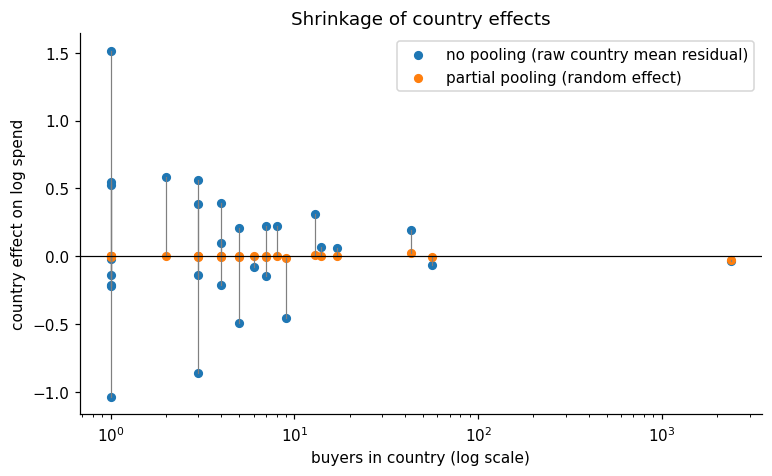

In [32]:
RHS_NO_UK = " + ".join(p for p in PREDICTORS if p != "is_uk")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")   # convergence/boundary warnings are common with few, small groups
    mixed = smf.mixedlm(f"log_spend ~ {RHS_NO_UK}", data=buyers, groups=buyers["country"]).fit(reml=True)
tau2, sigma2 = float(mixed.cov_re.iloc[0, 0]), float(mixed.scale)
print(f"Between-country variance tau² = {tau2:.4f}; residual variance sigma² = {sigma2:.4f}; "
      f"ICC = {tau2 / (tau2 + sigma2):.3f}")

# Raw country effect: mean residual from the mixed model's fixed part, so both columns share the same baseline
fixed_resid = buyers["log_spend"] - mixed.predict(buyers)
country = pd.DataFrame({
    "n_buyers": buyers.groupby("country").size(),
    "no_pooling": fixed_resid.groupby(buyers["country"]).mean(),
    "partial_pooling": pd.Series({c: float(np.asarray(v)[0]) for c, v in mixed.random_effects.items()}),
})
country["theoretical_shrinkage"] = tau2 / (tau2 + sigma2 / country["n_buyers"])
display(country.sort_values("n_buyers", ascending=False).head(12).round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
for c, row in country.iterrows():
    ax.plot([row["n_buyers"]] * 2, [row["no_pooling"], row["partial_pooling"]], color="grey", lw=0.8)
ax.scatter(country["n_buyers"], country["no_pooling"], label="no pooling (raw country mean residual)", s=25)
ax.scatter(country["n_buyers"], country["partial_pooling"], label="partial pooling (random effect)", s=25)
ax.axhline(0, color="k", lw=0.8)
ax.set_xscale("log")
ax.set(title="Shrinkage of country effects", xlabel="buyers in country (log scale)",
       ylabel="country effect on log spend")
ax.legend()
savefig(fig, "10_mixed_model_shrinkage")
RESULTS["mixed_model"] = {"tau2": tau2, "sigma2": sigma2, "icc": tau2 / (tau2 + sigma2),
                          "n_countries": int(len(country))}

**Notes.** Once customer behaviour is accounted for, country makes almost no difference to how much a customer spends. The between-country variance is tiny ($\tau^2 = 0.002$) compared with the variation between individual customers ($\sigma^2 = 0.717$), so country explains only about 0.3% of the remaining variation in log spend (ICC = 0.003). Put differently, a typical country's true effect is only around ±4–5% on spend ($\sqrt{0.002} \approx 0.045$). An estimate this close to zero is also uncertain, and the true between-country variance may well be zero. This matches the earlier models, where `is_uk` was never significant.

Because countries differ so little, the model shrinks their effects very strongly:

* **The UK** has enough customers (2,368) to keep 87% of its own estimate, which is close to zero anyway (−0.031 raw, −0.027 after pooling).
* **Germany and France**, the next largest groups with 56 and 43 buyers, keep only 13% and 11% of their raw effects. France's raw estimate of +0.20, which would mean about 22% higher spend, shrinks to +0.02.
* **The smallest countries** are pulled almost entirely to zero. In the chart, countries with only one to three buyers have raw effects ranging from −1.0 to +1.5 on the log scale, but these mostly reflect the luck of which few customers happened to be there, not real country differences. After partial pooling, all of them sit essentially on the zero line.

In every row, the partial-pooling effect equals the raw effect times the theoretical shrinkage factor (for France, 0.196 × 0.106 ≈ 0.021). The model is doing exactly what the formula in the markdown above describes.

**What this means.** There is no evidence that the retention team needs separate spending expectations by country. What a customer will spend is explained by how they bought in the past, not by where they are. The large raw differences between small countries are a good example of why adding a separate dummy for every country would have been misleading.

### Regression versus the purchase model: who predicts spend better?

We now have two completely different ways to predict how much each customer will spend in the holdout, and we compare them head to head:

* **Two-part regression.** The probability that a customer buys (from the logistic model) multiplied by how much they are expected to spend if they do buy (from the Gamma GLM). To keep the comparison fair, every customer's prediction comes from models fitted on the other customers, using 5-fold cross-validation.
* **BG/NBD.** The number of purchases the model expects from the customer in the holdout, multiplied by how much they spent per purchase occasion in the calibration period. A dedicated spend model (the Gamma–Gamma model) is usually paired with BG/NBD, but this simple version keeps the focus on the purchase model itself.

The two approaches don't learn from the same information:

* **The regression learns from holdout outcomes.** Even with cross-validation, it learns the link between past behaviour and future spend from other customers' holdout results. In practice, this means it needs an earlier period where the outcomes are already known to train on.
* **BG/NBD never sees the holdout at all.** It only uses each customer's own calibration history. So it can be used straight away, which is a real practical advantage. If the two models perform similarly, BG/NBD is the more impressive result.

**How we judge them.** For a retention budget, what matters most is whether a model picks out the right customers. So the main measure is **revenue captured**: rank all customers by each model's predicted spend, take the top 20%, and calculate what share of total holdout revenue those customers actually brought in. The higher the share, the better the model is at finding the customers who matter most.

,total predicted / actual,MAE (£),RMSE (£),Spearman,revenue captured by top 20%
Two-part GLM (cross-validated),0.829,678.655,3746.841,0.613,0.756
BG/NBD × spend per occasion,0.845,574.001,2471.777,0.625,0.760
Naive: calibration spend,2.525,1556.207,6080.663,0.573,0.752


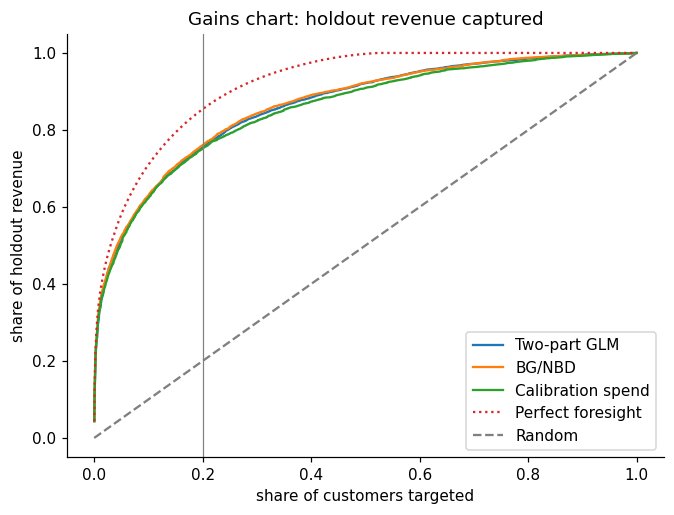

In [33]:
# Two-part model, predicted out of sample: P(buy) from a logistic GLM × E[spend | buy] from a Gamma GLM
data_tp = customers.assign(bought=customers["holdout_active"].astype(int))   # 0/1 response for the logit
twopart = pd.Series(0.0, index=customers.index)
for train_idx, test_idx in kf.split(data_tp):
    tr, te = data_tp.iloc[train_idx], data_tp.iloc[test_idx]
    p_buy = smf.glm(f"bought ~ {RHS}", data=tr, family=sm.families.Binomial()).fit().predict(te)
    tr_b = tr[tr["holdout_active"]]
    m_spend = smf.glm(f"holdout_spend ~ {RHS}", data=tr_b,
                      family=sm.families.Gamma(link=sm.families.links.Log())).fit().predict(te)
    twopart.loc[te.index] = p_buy * m_spend
customers["twopart_expected_spend"] = twopart
# BG/NBD predicts purchase days, so multiply by spend per purchase day (not per invoice)
customers["bg_expected_spend"] = customers["bg_expected_purchases"] * customers["spend_per_occasion"]


def evaluate(pred, actual, top=0.2):
    k = int(np.ceil(top * len(actual)))
    captured = actual.loc[pred.sort_values(ascending=False).index[:k]].sum() / actual.sum()
    return {"total predicted / actual": pred.sum() / actual.sum(),
            "MAE (£)": np.mean(np.abs(pred - actual)),
            "RMSE (£)": np.sqrt(np.mean((pred - actual) ** 2)),
            "Spearman": stats.spearmanr(pred, actual).statistic,
            f"revenue captured by top {int(top * 100)}%": captured}


actual_spend = customers["holdout_spend"]
spend_compare = pd.DataFrame({
    "Two-part GLM (cross-validated)": evaluate(customers["twopart_expected_spend"], actual_spend),
    "BG/NBD × spend per occasion": evaluate(customers["bg_expected_spend"], actual_spend),
    "Naive: calibration spend": evaluate(customers["calib_spend"], actual_spend),
}).T
display(spend_compare.round(3))

fig, ax = plt.subplots(figsize=(7, 5))
share = np.arange(1, len(customers) + 1) / len(customers)
for col, label in [("twopart_expected_spend", "Two-part GLM"), ("bg_expected_spend", "BG/NBD"),
                   ("calib_spend", "Calibration spend"), ("holdout_spend", "Perfect foresight")]:
    ranked = actual_spend.loc[customers[col].sort_values(ascending=False).index]
    ax.plot(share, ranked.cumsum() / actual_spend.sum(), label=label,
            ls=":" if label == "Perfect foresight" else "-")
ax.plot([0, 1], [0, 1], color="grey", ls="--", label="Random")
ax.axvline(0.2, color="grey", lw=0.8)
ax.set(title="Gains chart: holdout revenue captured", xlabel="share of customers targeted",
       ylabel="share of holdout revenue")
ax.legend()
savefig(fig, "11_gains_chart")
RESULTS["spend_models"] = spend_compare.round(4).to_dict(orient="index")

**Notes.** Both models do a good job of finding the most valuable customers, and so does simply ranking customers by past spend.

**Revenue captured.** Targeting the top 20% of customers by predicted spend captures about three-quarters of all holdout revenue with every method: 76.0% for BG/NBD, 75.6% for the two-part GLM, and 75.2% for calibration spend. A random 20% would capture only 20%, and perfect foresight would capture about 85%, so the models close most of the gap between random targeting and the best possible. In the gains chart the three curves are almost on top of each other, which shows that revenue is highly concentrated in a small group of customers and that past behaviour identifies that group well.

**Prediction accuracy.** BG/NBD is the better model on every measure. It has a lower average error (MAE of £574 vs £679), a much lower RMSE (£2,472 vs £3,747), and a slightly better ranking (Spearman 0.63 vs 0.61). The two-part GLM's much higher RMSE suggests it produces some very large predictions for a few customers. That is a known risk with log-link models when a customer's predictor values are unusual. Both models underpredict total holdout spend by about 15–17% (0.85 and 0.83), consistent with the Christmas peak and the few very large spenders that no model saw coming.

**Calibration spend as a baseline.** Its total is 2.5 times actual holdout spend, but that isn't a real error: the calibration period covers about 18 months against roughly 6 months of holdout, so the ratio mainly reflects the different lengths. It can only be judged on ranking, where it comes surprisingly close to the models (Spearman 0.57).

**What this means.** BG/NBD performs at least as well as the regression, even though it never sees any holdout outcomes, while the regression learned from other customers' holdout spend. That makes BG/NBD the more practical choice: it can be fitted on today's data and used right away, without waiting for an outcome period to train on. For targeting alone, though, any of the three rankings would serve the retention team about equally well.

## Sampling methods

### Which sampling design works best?

**The situation.** Suppose the retailer can only afford to look closely at a sample of customers, for example for a survey or a manual account review, and wants to use that sample to estimate **average holdout spend per customer**. In real life we would only see the sample. Here, though, we have every customer, so we know the true answer. That lets us test each sampling method by drawing many repeated samples (2,000 by default, set by `N_SIM_REPS`) of the same size (500, set by `SAMPLE_SIZE`) and checking how close each method gets to the truth.

We compare these approaches:

* **Simple random sampling (SRS).** Pick customers completely at random and use the sample average.
* **Stratified sampling by segment.** Split customers into the segments built earlier and sample from each segment separately. We try two ways of deciding how many customers to take from each segment:
  * **Proportional allocation:** each segment gets a share of the sample equal to its share of customers.
  * **Neyman allocation:** segments that are larger *and* more variable get more of the sample ($n_h \propto N_h S_h$, where $N_h$ is the segment size and $S_h$ its standard deviation). In practice we can't know how variable holdout spend is in each segment before sampling, so the **practical** version uses the variability of calibration spend instead. An **oracle** version, using the true holdout variability, shows the best that this approach could possibly do.
* **Ratio and regression estimators.** These still use simple random sampling, but they improve the estimate using calibration spend, which we already know for *every* customer. If the sample happens to contain customers who spent more than average in the past, these estimators adjust the result down accordingly, and vice versa.

For each method, the results table shows:

* **Bias:** on average, does the method hit the true value, or is it systematically too high or too low?
* **Standard error:** how much the estimate varies from sample to sample, both as observed across the simulations and as predicted by the textbook formula. If the two match, the formula can be trusted with a real single sample.
* **Design effect:** the method's variance divided by the variance of simple random sampling. A value below 1 means the method is more precise than SRS with the same sample size.
* **Coverage:** how often the method's 95% confidence interval actually contains the true value. A well-behaved method should be close to 95%.

In [34]:
class sampling:
    """Sampling designs for estimating a population mean: SRS, ratio, regression and stratified."""

    @staticmethod
    def _round_allocation(raw, N_h, n, min_per_stratum=2):
        """Round a real-valued allocation to integers that sum to n, with 2 <= n_h <= N_h."""
        floor = np.minimum(np.maximum(np.floor(raw), np.minimum(min_per_stratum, N_h)), N_h).astype(int)
        while floor.sum() < n:                         # hand out the remaining units by largest shortfall
            room = np.where(floor < N_h, raw - floor, -np.inf)
            floor[np.argmax(room)] += 1
        while floor.sum() > n:                         # take back units from the most over-allocated stratum
            excess = np.where(floor > np.minimum(min_per_stratum, N_h), floor - raw, -np.inf)
            floor[np.argmax(excess)] -= 1
        return floor

    @staticmethod
    def proportional_allocation(N_h, n):
        N_h = np.asarray(N_h)
        return sampling._round_allocation(n * N_h / N_h.sum(), N_h, n)

    @staticmethod
    def neyman_allocation(N_h, S_h, n):
        """n_h proportional to N_h * S_h (minimises the variance of the stratified mean)."""
        N_h, S_h = np.asarray(N_h), np.nan_to_num(np.asarray(S_h, dtype=float))
        w = N_h * S_h
        return sampling._round_allocation(n * w / w.sum(), N_h, n)

    @staticmethod
    def theoretical_variances(y, x, strata, n, allocations):
        """Textbook variances (with finite population correction) for each design."""
        N, f = len(y), n / len(y)
        S2_y = y.var(ddof=1)
        R = y.mean() / x.mean()
        rho = np.corrcoef(x, y)[0, 1]
        out = {"SRS: sample mean": (1 - f) * S2_y / n,
               "SRS: ratio estimator": (1 - f) * np.var(y - R * x, ddof=1) / n,
               "SRS: regression estimator": (1 - f) * S2_y * (1 - rho ** 2) / n}
        labels = np.unique(strata)
        N_h = np.array([np.sum(strata == h) for h in labels])
        S2_h = np.array([y[strata == h].var(ddof=1) for h in labels])
        W_h = N_h / N
        for name, n_h in allocations.items():
            out[name] = np.sum(W_h ** 2 * (1 - n_h / N_h) * S2_h / n_h)
        return pd.Series(out)

    @staticmethod
    def simulate_designs(y, x, strata, n, allocations, reps, rng):
        """Draw `reps` samples per design; return each replicate's estimate and estimated SE."""
        N, f = len(y), n / len(y)
        X_bar = x.mean()
        labels = np.unique(strata)
        idx_h = [np.flatnonzero(strata == h) for h in labels]
        N_h = np.array([len(i) for i in idx_h])
        W_h = N_h / N
        rows = []
        for rep in range(reps):
            s = rng.choice(N, n, replace=False)          # one SRS sample shared by the three SRS estimators
            ys, xs = y[s], x[s]
            y_bar, x_bar = ys.mean(), xs.mean()
            rows.append(("SRS: sample mean", rep, y_bar, np.sqrt((1 - f) * ys.var(ddof=1) / n)))

            r = y_bar / x_bar
            e = ys - r * xs
            rows.append(("SRS: ratio estimator", rep, r * X_bar, np.sqrt((1 - f) * e.var(ddof=1) / n)))

            b = np.cov(xs, ys, ddof=1)[0, 1] / xs.var(ddof=1)
            e = ys - y_bar - b * (xs - x_bar)
            rows.append(("SRS: regression estimator", rep, y_bar + b * (X_bar - x_bar),
                         np.sqrt((1 - f) * np.sum(e ** 2) / (n - 2) / n)))

            for name, n_h in allocations.items():
                means, var_terms = np.zeros(len(labels)), np.zeros(len(labels))
                for k, (idx, nk) in enumerate(zip(idx_h, n_h)):
                    yk = y[rng.choice(idx, nk, replace=False)]
                    means[k] = yk.mean()
                    var_terms[k] = W_h[k] ** 2 * (1 - nk / N_h[k]) * (yk.var(ddof=1) if nk > 1 else 0) / nk
                rows.append((name, rep, np.sum(W_h * means), np.sqrt(var_terms.sum())))
        return pd.DataFrame(rows, columns=["design", "rep", "estimate", "se"])

    @staticmethod
    def summarize_designs(sims, true_mean, theory):
        """Bias, empirical vs. estimated vs. theoretical SE, design effect and 95% CI coverage."""
        g = sims.groupby("design", sort=False)
        covered = ((sims["estimate"] - 1.96 * sims["se"] <= true_mean)
                   & (true_mean <= sims["estimate"] + 1.96 * sims["se"]))
        table = pd.DataFrame({
            "mean_estimate": g["estimate"].mean(),
            "bias": g["estimate"].mean() - true_mean,
            "relative_bias_%": 100 * (g["estimate"].mean() - true_mean) / true_mean,
            "empirical_SE": g["estimate"].std(ddof=1),
            "mean_estimated_SE": g["se"].mean(),
            "theoretical_SE": np.sqrt(theory),
        })
        table["design_effect"] = table["empirical_SE"] ** 2 / table.loc["SRS: sample mean", "empirical_SE"] ** 2
        table["coverage_95%"] = covered.groupby(sims["design"], sort=False).mean()
        return table


y = customers["holdout_spend"].to_numpy()
x_aux = customers["calib_spend"].to_numpy()
strata = customers["segment"].to_numpy()
N = len(y)
n = min(SAMPLE_SIZE, N // 4)
true_mean = y.mean()

labels = np.unique(strata)
N_h = np.array([np.sum(strata == h) for h in labels])
S_h_proxy = np.array([x_aux[strata == h].std(ddof=1) for h in labels])
S_h_oracle = np.array([y[strata == h].std(ddof=1) for h in labels])
allocations = {
    "Stratified: proportional": sampling.proportional_allocation(N_h, n),
    "Stratified: Neyman (proxy S_h)": sampling.neyman_allocation(N_h, S_h_proxy, n),
    "Stratified: Neyman (oracle S_h)": sampling.neyman_allocation(N_h, S_h_oracle, n),
}
display(pd.DataFrame(allocations, index=labels).assign(N_h=N_h))

theory = sampling.theoretical_variances(y, x_aux, strata, n, allocations)
sims = sampling.simulate_designs(y, x_aux, strata, n, allocations, N_SIM_REPS, rng)
design_table = sampling.summarize_designs(sims, true_mean, theory)
display(design_table.round(3))
print(f"True mean holdout spend: £{true_mean:,.2f};  N = {N:,};  n = {n}")
print(f"Correlation between calibration and holdout spend: {np.corrcoef(x_aux, y)[0, 1]:.3f}")

,Stratified: proportional,Stratified: Neyman (proxy S_h),Stratified: Neyman (oracle S_h),N_h
S1,93,7,14,914
S2,58,4,9,562
S3,30,11,10,294
S4,30,29,33,289
S5,65,14,19,640
S6,140,72,78,1374
S7,84,363,337,825


,mean_estimate,bias,relative_bias_%,empirical_SE,mean_estimated_SE,theoretical_SE,design_effect,coverage_95%
SRS: sample mean,910.323,-1.001,-0.110,215.650,186.593,220.651,1.000,0.790
SRS: ratio estimator,905.636,-5.689,-0.624,95.685,82.873,97.753,0.197,0.852
SRS: regression estimator,901.823,-9.501,-1.043,108.160,75.098,93.516,0.252,0.784
Stratified: proportional,915.378,4.053,0.445,215.516,186.952,216.666,0.999,0.786
Stratified: Neyman (proxy S_h),911.027,-0.298,-0.033,114.579,112.790,115.909,0.282,0.916
Stratified: Neyman (oracle S_h),914.696,3.371,0.370,113.042,111.485,113.012,0.275,0.924


True mean holdout spend: £911.32;  N = 4,898;  n = 500
Correlation between calibration and holdout spend: 0.906


**Notes.** The true average holdout spend is £911 per customer, and every design estimates it with very little bias: all are within about 1% of the truth on average. The differences between the designs are in precision and in how trustworthy their confidence intervals are.

**Allocations.** Neyman allocation moves most of the sample into the highest-value segment, S7: 363 of the 500 customers (about 44% of everyone in S7), compared with 84 under proportional allocation. The low-value segments S1 and S2 get only 7 and 4 customers. That is because spend varies far more in S7 than anywhere else, so that is where extra sampling reduces uncertainty most. The practical version, which uses calibration spend as a stand-in, chooses almost the same allocation as the oracle version that knows the true holdout variability. So calibration spend is a good guide for planning the sample.

**Precision.** Simple random sampling gives a standard error of about £216. The three methods that use calibration spend do much better:

* The **ratio estimator** is the most precise (SE £96, design effect 0.20). It gets about the same precision from 500 customers as simple random sampling would from roughly 2,500. This works because calibration and holdout spend are very strongly correlated (0.91).
* **Neyman stratified sampling** comes close (SE £113–115, design effect about 0.28), and the practical version loses almost nothing compared with the oracle.
* The **regression estimator** is in between (design effect 0.25).
* **Proportional stratification** gives no gain at all (design effect 1.00). The segments were built from buying *patterns*, not spend levels, and most of the variation in spend lies within segments, especially inside S7, rather than between them.

**Can the confidence intervals be trusted?** This is where the designs differ most. With very skewed spend, a sample of 500 often misses the few huge spenders. The sample then looks less variable than the population really is, so the estimated standard error is too small and the intervals too narrow. Simple random sampling covers the true mean only 79% of the time instead of 95%. The ratio estimator covers 85%. The regression estimator is worst: its estimated standard error (£75) is about 30% below its real variability (£108), and coverage is 78%. Neyman allocation is the exception. Because it samples nearly half of S7, where the big spenders are, its estimated standard errors match the real ones almost exactly (£113 vs £115), and coverage is 92%, close to the target 95%.

**Recommendation.** If the goal is the most precise single estimate, the ratio estimator is best. If the retailer also needs an honest measure of uncertainty, which is usually the case when reporting results, **Neyman stratified sampling using calibration spend** is the better choice: it is almost as precise, and it is the only design whose 95% intervals come close to deserving the name. A natural next step would be to combine the two, using a ratio estimator within each Neyman stratum.

,n for ±10% margin (±£91)
SRS: sample mean,3523
SRS: ratio estimator,1642
SRS: regression estimator,1919
Stratified: proportional,3522
Stratified: Neyman (proxy S_h),2055
Stratified: Neyman (oracle S_h),2023


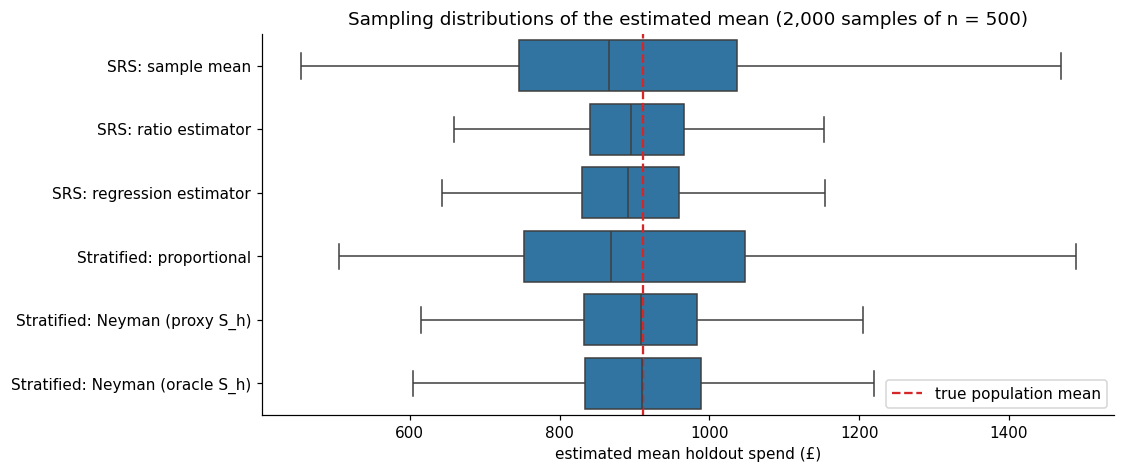

In [35]:
def required_sample_size(S2, N, margin, deff=1.0, z=1.96):
    """Smallest n giving a 95% margin of error of `margin` for a mean, scaled by the design effect,
    with the finite population correction: n = n0 / (1 + n0 / N), n0 = z^2 * S^2 * deff / margin^2."""
    n0 = z ** 2 * S2 * deff / margin ** 2
    return int(np.ceil(n0 / (1 + n0 / N)))

sampling.required_sample_size = staticmethod(required_sample_size)

fig, ax = plt.subplots(figsize=(10, 4.5))
order = list(design_table.index)
sns.boxplot(data=sims, x="estimate", y="design", order=order, ax=ax, showfliers=False)
ax.axvline(true_mean, color="C3", ls="--", label="true population mean")
ax.set(title=f"Sampling distributions of the estimated mean ({N_SIM_REPS:,} samples of n = {n})",
       xlabel="estimated mean holdout spend (£)", ylabel="")
ax.legend()
savefig(fig, "12_sampling_designs")

margin = 0.10 * true_mean
sizes = pd.Series({d: sampling.required_sample_size(y.var(ddof=1), N, margin, design_table.loc[d, "design_effect"])
                   for d in design_table.index}, name=f"n for ±10% margin (±£{margin:,.0f})")
display(sizes.to_frame())
RESULTS["sampling"] = {"n": int(n), "true_mean": float(true_mean),
                       "design_effect": design_table["design_effect"].round(4).to_dict(),
                       "ci_coverage_pct": (100 * design_table["coverage_95%"]).round(2).to_dict(),
                       "n_for_10pct_margin": sizes.to_dict()}

**Notes.** The boxplots show the 2,000 estimates from each design, with the true mean (£911) as the red dashed line.

**Shape of the sampling distributions.** Simple random sampling and proportional stratification are both very spread out: estimates range from about £450 to nearly £1,500. Their medians also sit well below the true mean, at around £865–870. Most random samples of 500 miss the handful of very large spenders and come out too low, while the occasional sample that catches several of them comes out far too high. On average this still balances out (bias is close to zero), but any single sample is likely to underestimate. This lopsided shape is also why their confidence intervals covered the truth only about 79% of the time.

The ratio and regression estimators are much tighter, with boxes roughly half as wide, though their medians are still slightly below the true mean. Neyman allocation is the only design whose distribution is centred right on the true mean and roughly symmetric. Because it samples nearly half of S7, it almost always includes the big spenders, which is why its intervals were the most reliable.

**Sample size needed for a ±10% margin (±£91).** Simple random sampling would need 3,523 customers, about 72% of all 4,898. At that point a sample saves little compared with reviewing everyone. Proportional stratification needs the same. The designs that use calibration spend cut this sharply: the ratio estimator needs about 1,640 customers (a third of the population), the regression estimator about 1,920, and Neyman allocation about 2,020–2,060. These numbers assume the confidence intervals work as intended. Since the SRS-based designs had coverage below 95%, they would in practice need somewhat more customers than shown.

**What 500 customers can actually deliver.** Using the standard errors from the simulation, a 500-customer sample gives a 95% margin of about ±£423 (±46%) with simple random sampling, ±£188 (±21%) with the ratio estimator, and ±£225 (±25%) with Neyman allocation.

**Recommendation.** Because spend is so skewed, estimating the average precisely is expensive whatever the design. Using calibration spend, either in the estimator (ratio) or in the design (Neyman), roughly halves the cost compared with simple random sampling. For a budget of around 500 reviews, Neyman stratified sampling is the safest choice: it gives a realistic margin of about ±25% together with an honest confidence interval.

### Bootstrap uncertainty

The two-part model gives a predicted holdout spend for every customer, and averaging these within each segment tells us what each segment is expected to be worth. But those predictions depend on model coefficients estimated from one particular set of customers. With a slightly different set of customers, the coefficients, and so the segment averages, would come out a bit differently. The bootstrap measures how much.

**Nonparametric bootstrap.** We create a new dataset by drawing customers at random from our own data *with replacement*, so some customers appear more than once and others not at all. We refit both parts of the model (the logistic and the Gamma GLM) on this new dataset, then recalculate each segment's average predicted holdout spend. We repeat this many times (200 by default, set by `N_BOOT`).

The spread of the results across repeats shows how uncertain each segment's estimate is because of having to estimate the model from limited data. We summarise it with a 95% interval: the range covering the middle 95% of the bootstrap results. A narrow interval means the segment's predicted value is stable. A wide one means it depends heavily on which customers happened to be in the data, which is likely for small segments or segments with a few very large spenders.

In [36]:
def bootstrap(data, statistic, n_boot, rng):
    """Nonparametric bootstrap: resample rows with replacement and recompute `statistic` each time.
    Resamples where a model fails to fit are skipped."""
    draws = []
    for _ in range(n_boot):
        sample = data.iloc[rng.integers(0, len(data), len(data))]
        try:
            draws.append(statistic(sample))
        except Exception:
            continue
    return np.array(draws)

def percentile_interval(draws, level=0.95):
    """Percentile bootstrap interval for each column of `draws`."""
    alpha = (1 - level) / 2
    return np.column_stack([np.nanquantile(draws, alpha, axis=0), np.nanquantile(draws, 1 - alpha, axis=0)])

sampling.bootstrap = staticmethod(bootstrap)
sampling.percentile_interval = staticmethod(percentile_interval)


def segment_value(sample):
    p_buy = smf.glm(f"bought ~ {RHS}", data=sample, family=sm.families.Binomial()).fit().predict(customers)
    b = sample[sample["holdout_active"]]
    spend = smf.glm(f"holdout_spend ~ {RHS}", data=b,
                    family=sm.families.Gamma(link=sm.families.links.Log())).fit().predict(customers)
    return (p_buy * spend).groupby(customers["segment"]).mean().reindex(SEGMENTS).to_numpy()


boot_data = customers.assign(bought=customers["holdout_active"].astype(int))   # 0/1 response for the logit
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    point = segment_value(boot_data)
    draws = sampling.bootstrap(boot_data, segment_value, N_BOOT, rng)
ci = sampling.percentile_interval(draws)
boot_table = pd.DataFrame({"estimate": point, "boot_SE": draws.std(axis=0, ddof=1),
                           "ci_lower": ci[:, 0], "ci_upper": ci[:, 1],
                           "actual_mean_holdout_spend": customers.groupby("segment")["holdout_spend"].mean()
                                                                 .reindex(SEGMENTS).to_numpy()},
                          index=SEGMENTS)
display(boot_table.round(2))
print(f"Successful bootstrap resamples: {len(draws)} of {N_BOOT}")
RESULTS["bootstrap_segment_value"] = boot_table.round(2).to_dict(orient="index")

,estimate,boot_SE,ci_lower,ci_upper,actual_mean_holdout_spend
S1,149.11,9.26,131.88,170.37,163.54
S2,157.30,12.54,136.17,183.27,158.01
S3,538.57,30.47,478.89,596.82,363.59
S4,946.79,157.34,655.23,1194.60,654.36
S5,493.80,18.47,459.13,529.41,454.33
S6,770.46,19.30,736.05,808.26,765.57
S7,2033.70,73.51,1887.97,2173.96,3135.42


Successful bootstrap resamples: 200 of 200


**Notes.** All 200 bootstrap resamples fitted successfully. The table shows each segment's average predicted holdout spend from the two-part model, its bootstrap 95% interval, and what customers in that segment actually spent.

**How uncertain are the estimates?** For most segments the intervals are fairly narrow: the bootstrap standard error is 2–8% of the estimate for S1, S2, S3, S5, S6 and S7. S4 is the exception. Its standard error is £157, about 17% of the estimate, with an interval from £655 to £1,195. S4 is the small, scattered segment of unusual customers we saw in the PCA plot, so its predicted value depends heavily on which of its few extreme customers end up in each resample.

**Ranking of segments.** The ranking is clear despite the uncertainty. S7 is by far the most valuable segment (about £2,000 predicted per customer). S6 and S4 come next (£770–950), then S3 and S5 (about £490–540), with S1 and S2 well behind (about £150–160). Most intervals don't overlap, so this ordering is not a product of chance.

**Comparison with actual spend.** For S1, S2 and S6, actual spend falls inside the interval, and S5 is only just below it. Three segments are clearly off:

* **S3 and S4 are overpredicted.** Actual spend is £364 and £654, about 30–50% below the estimates, and below (or right at the edge of) their intervals.
* **S7 is strongly underpredicted.** Its customers actually spent £3,135 on average, about 50% more than predicted and far above the top of the interval (£2,174).

These gaps are much larger than the bootstrap intervals, which shows what the bootstrap does and doesn't measure. It captures uncertainty from estimating the coefficients, but not errors from the model's structure. The two-part model uses the same coefficients for every customer, so it can't fully capture how extreme spending gets among the top customers in S7, and it spreads some of that value onto other segments.

**What this means for the retention team.** S7 is clearly the segment to prioritise, and its true value is likely even higher than the model suggests. The narrow intervals shouldn't be read as proof that the predicted values are accurate: they only show that the model's estimates are stable, not that the model is right.

**Parametric bootstrap (BG/NBD).** For the BG/NBD model we use a different kind of bootstrap. Instead of resampling our real customers, we use the fitted model to *generate* new, artificial purchase histories. Each simulated customer is observed for the same length of time ($T$) as a real customer, and buys and drops out according to the estimated parameters. We fit the model to this simulated data, record the new parameter estimates, and repeat many times (100 by default, set by `N_PARAM_BOOT`).

This does two things:

* **It checks the standard errors.** The spread of the parameter estimates across simulations gives a second, independent estimate of their standard errors. If it is close to the standard errors from the Hessian, we can trust those.
* **It shows how parameter uncertainty affects the forecast.** For each set of re-estimated parameters, we recompute the total number of purchases expected in the holdout. The spread of these totals gives a 95% interval for the forecast.

That interval only reflects uncertainty about the model's parameters. It does not include the natural randomness in whether and when individual customers actually buy, which adds a lot more uncertainty. So it is narrower than a full prediction interval, and the actual total can fall outside it even if the model is working well.

In [37]:
def simulate(params, T, rng):
    """Simulate (x, t_x) for customers observed for T weeks under the BG/NBD model (vectorised)."""
    r, alpha, a, b = params
    T = np.asarray(T, float)
    n = len(T)
    lam = rng.gamma(r, 1 / alpha, n)                  # each customer's purchase rate while alive
    p = rng.beta(a, b, n)                             # each customer's dropout probability after a purchase
    x, t_x, t = np.zeros(n), np.zeros(n), np.zeros(n)
    active = np.ones(n, dtype=bool)
    while active.any():
        idx = np.flatnonzero(active)
        t[idx] += rng.exponential(1 / lam[idx])
        past_end = t[idx] > T[idx]
        active[idx[past_end]] = False                 # next purchase falls after the observation window
        buy = idx[~past_end]
        x[buy] += 1
        t_x[buy] = t[buy]
        active[buy[rng.random(len(buy)) < p[buy]]] = False   # leaves for good after this purchase
    return x, t_x

bgnbd.simulate = staticmethod(simulate)

# Parametric bootstrap: simulate customers from the fitted model, refit, and repeat
boot_params, boot_totals = [], []
for _ in range(N_PARAM_BOOT):
    xs, txs = bgnbd.simulate(bg.params, T, rng)
    fb = bgnbd.fit(xs, txs, T, start=bg.params)
    boot_params.append(fb.params)
    boot_totals.append(bgnbd.conditional_expected_purchases(fb.params, H, x, t_x, T).sum())
boot_params = np.array(boot_params)
boot_totals = np.array(boot_totals)

param_table = bg.summary()[["estimate", "std_error"]].rename(columns={"std_error": "SE_hessian"})
param_table["SE_parametric_bootstrap"] = boot_params.std(axis=0, ddof=1)
display(param_table.round(4))

lo, hi = np.percentile(boot_totals, [2.5, 97.5])
print(f"Total predicted holdout purchases: {customers['bg_expected_purchases'].sum():,.0f} "
      f"(95% parameter-uncertainty interval {lo:,.0f} to {hi:,.0f}); actual: {customers['holdout_purchases'].sum():,}")
RESULTS["bgnbd_parametric_bootstrap"] = {
    "se": dict(zip(bgnbd.PARAM_NAMES, boot_params.std(axis=0, ddof=1).round(5).tolist())),
    "total_purchases_interval": [float(lo), float(hi)]}

,estimate,SE_hessian,SE_parametric_bootstrap
r,0.6880,0.0193,0.0182
alpha,9.5959,0.3359,0.3290
a,0.1520,0.0294,0.0438
b,3.1948,0.9005,1.5360


Total predicted holdout purchases: 7,887 (95% parameter-uncertainty interval 7,737 to 8,028); actual: 8,071


**Notes.** The parametric bootstrap gives a second estimate of each parameter's standard error, to check against the ones from the Hessian.

**Buying parameters ($r$, $\alpha$).** The two methods agree closely: 0.018 vs 0.019 for $r$, and 0.33 vs 0.34 for $\alpha$. So the Hessian-based standard errors for the purchase-rate side of the model can be trusted.

**Dropout parameters ($a$, $b$).** Here the bootstrap gives clearly larger standard errors: about 50% larger for $a$ (0.044 vs 0.029) and about 70% larger for $b$ (1.54 vs 0.90). The Hessian method assumes the likelihood has a simple, symmetric shape around the best estimate. For the dropout parameters it doesn't: we never actually see customers leave, so the data pin these parameters down only loosely, especially on the high side of $b$. In other words, the Hessian makes the dropout part of the model look more precise than it really is, and the 95% interval for $b$ reported earlier (1.8 to 5.6) is probably too narrow. This reinforces the earlier finding that dropout is the least certain part of the model.

**Forecast of total holdout purchases.** Accounting for parameter uncertainty, the model expects 7,887 purchases, with a 95% interval of 7,737 to 8,028, only about ±2% around the estimate. The forecast is therefore not very sensitive to the exact parameter values. The actual total of 8,071 lies just above this interval. Parameter uncertainty alone can't explain the gap, which points instead to the model's assumptions, most likely the steady purchase rate that ignores the Christmas peak, as seen in the Markov chain seasonality test. As explained above, this interval also leaves out the natural randomness of individual purchases. Once that is included, a full prediction interval would be wider, and a gap of about 2% would very likely fall within it.

## Recommendation: who should get the retention budget?

Now we bring everything together into a practical targeting plan, built from two lists:

* **The customers worth the most.** We rank every customer by predicted holdout spend, using whichever spend model did better at capturing revenue in the comparison above (two-part regression or BG/NBD). The top 20% of this ranking is the main target list: these are the customers expected to bring in the most revenue, so keeping them engaged matters most.
* **Valuable customers who may be slipping away.** We also look at customers who were high spenders in the calibration period (the top 20% by past spend), but whom the BG/NBD model now considers more likely gone than active ($P(\text{alive}) < 0.5$). These customers were valuable in the past but have gone unusually quiet given how often they used to buy. They are natural candidates for a win-back campaign before they are lost for good.

Because we know what actually happened in the holdout, we can check how well this plan would have worked: how much of the holdout revenue came from the targeted customers, and how many of the at-risk customers really did fail to return. Finally, we save each customer's scores and all key results to the `results/` folder so the retention team can use them directly.

In [38]:
model_cols = {"Two-part GLM (cross-validated)": "twopart_expected_spend",
              "BG/NBD × spend per occasion": "bg_expected_spend"}
capture_col = [c for c in spend_compare.columns if c.startswith("revenue captured")][0]
best_model = spend_compare.loc[list(model_cols), capture_col].idxmax()
customers["predicted_value"] = customers[model_cols[best_model]]

top_n = int(np.ceil(0.2 * len(customers)))
target = customers.nlargest(top_n, "predicted_value")
high_value = customers["calib_spend"] >= customers["calib_spend"].quantile(0.8)
at_risk = customers[high_value & (customers["p_alive"] < 0.5)]

summary = pd.Series({
    "ranking model": best_model,
    "customers targeted (top 20%)": top_n,
    "share of holdout revenue from targeted customers": target["holdout_spend"].sum() / actual_spend.sum(),
    "high-value customers flagged at risk (P(alive) < 0.5)": len(at_risk),
    # guard against an empty at-risk group (the mean of an empty column would be NaN)
    "share of at-risk high-value customers who did not return":
        1 - at_risk["holdout_active"].mean() if len(at_risk) else 0.0,
    "calibration revenue of at-risk high-value customers (£)": at_risk["calib_spend"].sum(),
})
display(summary.to_frame("value"))
display(target["segment"].value_counts(normalize=True).rename("segment mix of targeted customers").to_frame())

export_cols = ["segment", "p_alive", "bg_expected_purchases", "bg_expected_spend", "twopart_expected_spend",
               "markov_p_any", "holdout_purchases", "holdout_spend"]
customers[export_cols].to_csv(RESULTS_DIR / "customer_scores.csv")
RESULTS["recommendation"] = {k: (v if isinstance(v, str) else float(v)) for k, v in summary.items()}
with open(RESULTS_DIR / "summary.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=float)
print(f"Saved results/summary.json, results/customer_scores.csv and {len(list(FIG_DIR.glob('*.png')))} figures.")

,value
ranking model,BG/NBD × spend per occasion
customers targeted (top 20%),980
share of holdout revenue from targeted customers,0.760278
high-value customers flagged at risk (P(alive) < 0.5),37
share of at-risk high-value customers who did not return,0.783784
calibration revenue of at-risk high-value customers (£),408037.97


,segment mix of targeted customers
segment,
S7,0.472449
S6,0.347959
S5,0.085714
S1,0.029592
S3,0.029592
S4,0.027551
S2,0.007143


Saved results/summary.json, results/customer_scores.csv and 13 figures.


**Notes.** The recommendation uses the BG/NBD ranking, which captured slightly more holdout revenue than the two-part regression in the earlier comparison.

**The main target list.** The top 20% of customers by predicted value, 980 people, brought in 76% of all holdout revenue. A retention budget aimed at one customer in five would therefore cover three-quarters of the revenue at stake. The list is concentrated in two segments: S7 makes up 47% of it and S6 35%, so together they account for over 80% of the targeted customers. More than half of all S7 customers (about 460 of 825) make the list, and about a quarter of S6. S5 contributes 9%, and the other segments only 1–3% each.

The model ranks individual customers, not whole segments. It still picks out about 29 customers from S1, the lowest-value segment, and only about 27 from S4, even though S4 had a high average predicted value in the bootstrap. Within each segment, customers differ a lot, so scoring them one by one finds valuable customers that segment-level targeting would miss, and leaves out weaker ones it would include.

**The at-risk list.** 37 customers were among the top 20% of spenders in calibration but had a P(alive) below 0.5 by the end of May. The warning proved accurate: 29 of them (78%) made no purchase at all in the holdout, compared with about 47% of all customers. These 37 customers had spent £408,000 in calibration, about £11,000 each on average, so even winning back a few of them would be worth a lot. Because the list is so short, the retention team could contact them personally rather than through a general campaign.

This list is cautious rather than complete. As we saw earlier, BG/NBD gives most customers a P(alive) close to 1, and every one-time buyer exactly 1, so many customers who are actually lapsing are never flagged. A stricter cut-off, or combining P(alive) with the Markov chain's months-since-last-purchase, would catch more of them.

**Overall recommendation.** Focus the main retention budget on the top 20% by BG/NBD predicted value, mostly S7 and S6 customers. Alongside it, run a small, personal win-back effort for the 37 high-value customers flagged as at risk. Timing matters: the Markov chain showed that lapsed customers are about twice as likely to return in Q4, so the weeks before the Christmas season are the best moment to reach them.

### Key findings

1. **Segments:** Customers fall into seven behaviour-based segments that differ clearly in what they do next (MANOVA p < 0.001), mainly in how active they stay, and two segments, S7 and S6, make up over 80% of the customers worth targeting.
2. **Who comes back:** Recency and frequency matter most. Each extra month without a purchase cuts the odds of returning by about 13%, the monthly chance of buying falls from 38% just after a purchase to 7% after six quiet months, and doubling past purchase occasions roughly doubles the odds of coming back. Price level, return rate and country make little difference.
3. **Where the stochastic model breaks:** BG/NBD assumes steady, random buying, but 23% of frequent customers buy on a more regular schedule than that (mostly in S7 and S6), lapsed customers are twice as likely to return in Q4, and the model can't tell when one-time buyers have left. As a result, it slightly underpredicts the Christmas period and is overconfident about how long customers stay.
4. **Regression vs stochastic model:** BG/NBD performs at least as well as the two-part regression. Its top 20% captures 76% of holdout revenue, against 75.6% for the regression, with lower average error (£574 vs £679), and it never needs to see future outcomes to train, so it can be used straight away.
5. **Measuring value cheaply:** Because spend is so skewed, a simple random sample would need about 72% of customers to estimate average spend within ±10%. Stratifying by segment with Neyman allocation based on past spend gives a ±25% estimate from just 500 customers, with confidence intervals that can actually be trusted (92% coverage).
6. **Recommendation:** Focus the retention budget on the top 20% of customers by BG/NBD predicted value (980 customers, 76% of holdout revenue, mostly S7 and S6). Alongside it, run a personal win-back effort for the 37 high-value customers flagged as at risk, who spent £408,000 in calibration and 78% of whom did not return, ideally just before the Q4 season.

### Limitations

* **Left-censoring.** The data start in December 2009, so for customers who were already buying before then, their "first purchase" is just the first one we can see. This makes their tenure look shorter than it really is.
* **Wholesale and retail customers mixed together.** One BG/NBD model is fitted to everyone, even though the Poisson test showed that frequent (often wholesale) customers buy on a much more regular schedule than occasional ones.
* **Seasonality is ignored.** Both BG/NBD and the Markov chain assume buying behaviour doesn't change with the calendar, but the Q4 test showed it clearly does. This is the most likely reason both models underpredicted the holdout.
* **Simple spend model.** The BG/NBD spend forecast uses each customer's average spend per occasion from calibration. For customers with only one or two purchases, that average is noisy. A Gamma–Gamma model would pull such averages towards the overall mean.
* **P(alive) is optimistic.** In BG/NBD, customers can only leave after a repeat purchase, so every one-time buyer has P(alive) = 1. The at-risk list therefore misses many customers who are actually lapsing.
* **One holdout period.** All models are tested on a single June–December 2011 period that includes the Christmas peak, so results may differ for a quieter period.
* **Partial final month.** The data end on 9 December 2011, so the last holdout month only covers nine days.

### Extensions

* Fit BG/NBD separately for each segment, or let the purchase and dropout rates depend on customer characteristics, so that wholesale and retail customers aren't forced into one model.
* Replace the random (Poisson) timing assumption with one that allows more regular gaps between purchases (for example, Erlang-distributed gaps), to better fit customers who reorder on a schedule.
* Add a Gamma–Gamma model for spend per purchase, to make spend forecasts more reliable for customers with few purchases.
* Use a seasonal Markov chain with a separate transition matrix for each quarter, and test whether next month's buying depends only on the current state (first-order) or also on the month before (second-order).
* Combine the at-risk signals: use both BG/NBD's P(alive) and the Markov chain's months since last purchase to catch lapsing customers that P(alive) alone misses.
* Combine stratification with the ratio or regression estimator (estimating within each Neyman stratum), to get the precision of the ratio estimator together with the reliable confidence intervals of stratified sampling.